# Session-to-session drift in motor-imagery decoding (BNCI2014-004) — full study

**ROBT613 Midterm Project** · Team: Sultanbek, Aruzhan, Daniela, Aidarkhan · Dataset: BNCI2014-004 (BCI Competition IV 2b, Graz)

---
## 0. Research question, hypotheses and decision rules

**Problem.** A BCI is calibrated on one day and used on later days. Between days the electrodes sit slightly differently, impedance
and fatigue change, and people learn — so the EEG features a decoder relies on can shift. This is *session-to-session drift*.
If it is real, a decoder trained on an earlier day should perform worse on a new day than a decoder trained on that same day.

**History (disclosed).** A first version of this study (v1) used MOABB's ready-made epochs, an EOG correction fitted on task data,
no trial cleaning and imprecise band edges. It found no drift on day 1 → day 2. The hypotheses below were written before v1's
results and are kept unchanged. What is new: the data preparation is the one fixed (independently of this question) for our
second study, and H1b — drift inside the feedback paradigm — was added and fixed before running it for the first time.

| | Hypothesis | Test |
|---|---|---|
| **H1a** (primary) | Trained on session 1, tested on session 2 (both screening, different days): ROC AUC is **lower** than within-session cross-validation on session 2, with the same number of training trials. | drift cost = within − cross; one-sided Wilcoxon over 9 subjects, α = 0.05 |
| **H1b** (secondary, new) | Same, inside the feedback paradigm: trained on session 3, tested on sessions 4 and 5 (averaged). | same |
| **H2** (fixes) | Two label-free fixes reduce the drift cost: **C** baseline-relative power (log power 3.5–5.5 s minus 0.5–1.5 s) and **D** per-session z-scoring of features (the team's README hypothesis). | drift cost averaged over both transfers; one-sided Wilcoxon per fix, Holm-corrected; cross-session AUC must not drop significantly (descriptive check) |

Secondary metric everywhere: balanced accuracy at the default threshold. AUC only asks whether right-hand trials score higher than
left-hand trials; if a new day shifts **all** scores together, AUC stays the same but accuracy drops. Comparing the two tells us
*which kind* of drift we see.

**Methods.** Notebooks 00–06 of the [ROBT613 BCI Workshop](https://berdakh.github.io/ROBT613-BCI-Workshop/) (MNE data model, FIR
filtering, EOG regression, epoching and QC, Welch log band power, logistic regression, grouped cross-validation); `.mat` loading as
in the course lecture *Motor-Imagery BCI decoding with CSP and LDA*; cross-validation from the scikit-learn lectures.

## 1. Setup

In [1]:
import importlib, subprocess, sys
for pkg in ["mne", "moabb", "nilearn"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import warnings
warnings.filterwarnings("ignore")
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, FancyBboxPatch, Rectangle
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from IPython.display import display
from scipy.io import loadmat
from scipy.signal import hilbert
from scipy.fft import next_fast_len
from scipy.stats import wilcoxon, mannwhitneyu, rankdata
import mne
from mne.preprocessing import EOGRegression
from mne.time_frequency import psd_array_welch
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, cohen_kappa_score

mne.set_log_level("ERROR")
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("MNE", mne.__version__, "| numpy", np.__version__)

MNE 1.13.2 | numpy 2.5.3


### All analysis settings in one place
Fixed in the analysis plan. Changing any of them is a different analysis.

In [2]:
SEED = 42
SUBJECTS = list(range(1, 10))
SESSIONS = [1, 2, 3, 4, 5]
SESS_TYPE = {1: "screening", 2: "screening", 3: "feedback", 4: "feedback", 5: "feedback"}
RUN_LEN = {"screening": 20, "feedback": 40}       # trials per run (block) in recording order
CH_EEG, CH_EOG = ["C3", "Cz", "C4"], ["EOG1", "EOG2", "EOG3"]

L_FREQ, H_FREQ = 1.0, 40.0          # band-pass of the continuous signal
EPOCH_LEN = 7.5                     # s, epochs 0–7.5 s from trial start
FEAT_WIN = (3.5, 5.5)               # s, feature window (imagery)
BASE_WIN = (0.5, 1.5)               # s, pre-cue baseline for fix C (v1 definition)
MIN_CALIB_S = 60                    # s, minimum pre-trial EOG calibration segment
ROBUST_Z = 5.0                      # robust-SD limit for trial log-variance outliers

BANDS = [(8, 13), (13, 31)]         # 1-Hz bins 8–12 Hz and 13–30 Hz inclusive (masks are half-open [lo, hi))
FEATURE_NAMES = [f"{b}_{ch}" for b in ("mu", "beta") for ch in CH_EEG]
TRANSFERS = {"S1→S2": (1, [2]), "S3→S4/S5": (3, [4, 5])}      # (training session, scored sessions)
VARIANTS = {"A": "raw log power", "C": "baseline-relative", "D": "session z-scored"}
N_REP = 20                          # repeated class-stratified subsamples when matching training size
N_SHUFFLE = 20
ALPHA = 0.05

### Plot helpers (head drawings)
2-D head seen from above, nose up, electrodes at their standard 10–20 positions.

In [3]:
_MONTAGE = mne.channels.make_standard_montage("standard_1020")
_POS3D = _MONTAGE.get_positions()["ch_pos"]
GRID_10_20 = ["Fp1", "Fpz", "Fp2", "F7", "F3", "Fz", "F4", "F8", "T7", "C5", "C3", "C1", "Cz", "C2", "C4", "C6", "T8",
              "P7", "P3", "Pz", "P4", "P8", "O1", "Oz", "O2", "FC3", "FCz", "FC4", "CP3", "CPz", "CP4"]

def _theta(name):
    x, y, z = _POS3D[name]
    return np.arccos(z / np.sqrt(x * x + y * y + z * z))

_THETA_MAX = max(_theta(n) for n in ["Fp1", "Fpz", "Fp2", "F7", "F8", "T7", "T8", "P7", "P8", "O1", "Oz", "O2"])

def head_xy(name):
    x, y, z = _POS3D[name]
    rho = _theta(name) / _THETA_MAX * 0.46
    phi = np.arctan2(y, x)
    return rho * np.cos(phi), rho * np.sin(phi)

def draw_head(ax, grid=True, strip=True):
    ax.add_patch(Circle((0, 0), 0.5, fill=False, lw=1.5, color="k"))
    ax.plot([-0.07, 0, 0.07], [0.495, 0.58, 0.495], color="k", lw=1.5)
    for side in (-1, 1):
        ax.add_patch(Ellipse((side * 0.53, 0), 0.06, 0.2, fill=False, lw=1.5, color="k"))
    if strip:
        xs, ys = zip(*[head_xy(n) for n in ["T7", "C5", "C3", "C1", "Cz", "C2", "C4", "C6", "T8"]])
        ax.plot(xs, ys, color="orange", lw=22, alpha=0.15, solid_capstyle="round", zorder=0)
    if grid:
        for n in GRID_10_20:
            if n not in CH_EEG:
                x, y = head_xy(n); ax.plot(x, y, "o", color="lightgrey", ms=4, zorder=1)
    ax.set_xlim(-0.66, 0.66); ax.set_ylim(-0.6, 0.66); ax.set_aspect("equal"); ax.axis("off")

def head_values(ax, values, cmap="RdBu_r", vmin=-50, vmax=50, title="", fmt="{:+.0f}%"):
    draw_head(ax)
    norm = Normalize(vmin, vmax)
    for ch, v in values.items():
        x, y = head_xy(ch)
        ax.add_patch(Circle((x, y), 0.075, color=plt.get_cmap(cmap)(norm(v)), ec="k", lw=1, zorder=3))
        ax.text(x, y - 0.13, f"{ch}\n" + fmt.format(v), ha="center", va="top", fontsize=8)
    ax.set_title(title, fontsize=10)
    return ScalarMappable(norm=norm, cmap=cmap)

## 2. Study design at a glance

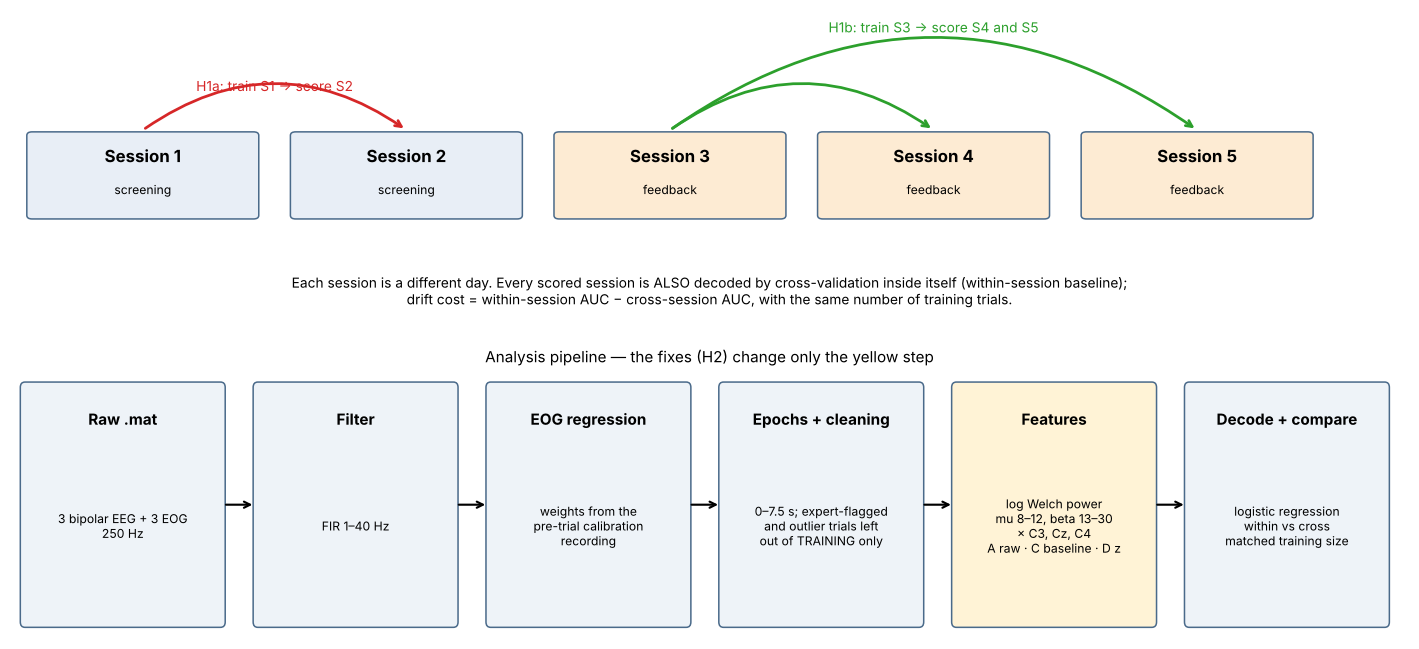

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), gridspec_kw={"height_ratios": [1.2, 1]})
ax = axes[0]; ax.axis("off"); ax.set_xlim(0, 5.3); ax.set_ylim(-0.35, 1.45)
for i, s in enumerate(SESSIONS):
    ax.add_patch(FancyBboxPatch((i + 0.08, 0.3), 0.84, 0.45, boxstyle="round,pad=0.02",
                                fc="#e8eef6" if s <= 2 else "#fdebd3", ec="#4a6a8a"))
    ax.text(i + 0.5, 0.6, f"Session {s}", ha="center", fontsize=11, weight="bold")
    ax.text(i + 0.5, 0.42, SESS_TYPE[s], ha="center", fontsize=8)
for (a, b), col in [((0, 1), "C3"), ((2, 3), "C2"), ((2, 4), "C2")]:
    ax.annotate("", (b + 0.5, 0.78), (a + 0.5, 0.78),
                arrowprops=dict(arrowstyle="->", lw=1.8, color=col, connectionstyle="arc3,rad=-0.35"))
ax.text(1.0, 1.0, "H1a: train S1 → score S2", ha="center", fontsize=9, color="C3")
ax.text(3.5, 1.33, "H1b: train S3 → score S4 and S5", ha="center", fontsize=9, color="C2")
ax.text(2.65, -0.2, "Each session is a different day. Every scored session is ALSO decoded by cross-validation inside itself "
        "(within-session baseline);\ndrift cost = within-session AUC − cross-session AUC, with the same number of training trials.",
        ha="center", fontsize=9)

ax = axes[1]; ax.axis("off"); ax.set_xlim(0, 6); ax.set_ylim(0, 1)
steps = [("Raw .mat", "3 bipolar EEG + 3 EOG\n250 Hz"), ("Filter", "FIR 1–40 Hz"),
         ("EOG regression", "weights from the\npre-trial calibration\nrecording"),
         ("Epochs + cleaning", "0–7.5 s; expert-flagged\nand outlier trials left\nout of TRAINING only"),
         ("Features", "log Welch power\nmu 8–12, beta 13–30\n× C3, Cz, C4\nA raw · C baseline · D z"),
         ("Decode + compare", "logistic regression\nwithin vs cross\nmatched training size")]
for i, (h, b) in enumerate(steps):
    ax.add_patch(FancyBboxPatch((i + 0.06, 0.06), 0.84, 0.88, boxstyle="round,pad=0.02",
                                fc="#fff3d6" if h == "Features" else "#eef3f8", ec="#4a6a8a"))
    ax.text(i + 0.48, 0.8, h, ha="center", fontsize=10, weight="bold")
    ax.text(i + 0.48, 0.42, b, ha="center", va="center", fontsize=8)
    if i < len(steps) - 1:
        ax.annotate("", (i + 1.05, 0.5), (i + 0.91, 0.5), arrowprops=dict(arrowstyle="->", lw=1.4))
ax.set_title("Analysis pipeline — the fixes (H2) change only the yellow step", fontsize=10)
plt.tight_layout(); plt.show()

## 3. Load the data directly from the original files
We read the competition `.mat` files ourselves (as in the course lecture) instead of using MOABB's ready-made epochs, so we keep
every field the authors provide: the signal, trial onsets, labels, **expert artifact flags**, age and gender.
MOABB is used only to download the files (or find them if they are already in `~/mne_data`).

In [5]:
from moabb.datasets import BNCI2014_004

def mat_files(subject):
    """Return [B0xT.mat, B0xE.mat]: use local copies if present, otherwise download through MOABB."""
    root = Path(mne.get_config("MNE_DATA") or Path.home() / "mne_data")
    local = [root / "MNE-bnci-data" / "~bci" / "database" / "004-2014" / f"B{subject:02d}{s}.mat" for s in "TE"]
    if all(p.exists() for p in local):
        return local
    return [Path(p) for p in BNCI2014_004().data_path(subject)]

def load_subject(subject):
    out = {}
    s = 1
    for f in mat_files(subject):
        runs = loadmat(f, struct_as_record=False, squeeze_me=True)["data"]
        runs = runs if isinstance(runs, np.ndarray) else [runs]
        for r in runs:
            assert f.name.endswith("T.mat") == (s <= 3), "session order: B0xT must hold sessions 1–3, B0xE sessions 4–5"
            trial = np.atleast_1d(r.trial).astype(int) - 1          # MATLAB 1-based -> 0-based samples
            if trial.size == 0:
                continue
            out[s] = dict(X=np.asarray(r.X, float), onsets=trial, y=np.atleast_1d(r.y).astype(int) - 1,  # 0 left, 1 right
                          artifacts=np.atleast_1d(r.artifacts).astype(bool), fs=float(r.fs),
                          gender=str(r.gender), age=int(r.age), file=f.name)
            s += 1
    assert sorted(out) == SESSIONS, f"subject {subject}: found sessions {sorted(out)}"
    return out

t0 = time.time()
data = {subj: load_subject(subj) for subj in SUBJECTS}
print(f"Loaded 9 subjects × 5 sessions in {time.time() - t0:.0f} s")

Loaded 9 subjects × 5 sessions in 6 s


In [6]:
rows = []
for subj in SUBJECTS:
    for s in SESSIONS:
        d = data[subj][s]
        rows.append(dict(subject=subj, session=s, type=SESS_TYPE[s], file=d["file"], fs=d["fs"],
                         minutes=len(d["X"]) / d["fs"] / 60, trials=len(d["y"]), left=int((d["y"] == 0).sum()),
                         right=int((d["y"] == 1).sum()), expert_flagged=int(d["artifacts"].sum()),
                         first_trial_s=d["onsets"][0] / d["fs"], age=d["age"], gender=d["gender"]))
audit = pd.DataFrame(rows)
assert (audit.fs == 250).all() and (audit.left == audit.right).all()
print("Participants:", ", ".join(f"S{r.subject}: {r.gender}, {r.age} y" for r in audit[audit.session == 1].itertuples()))
audit.pivot(index="subject", columns="session", values="trials")

Participants: S1: female, 20 y, S2: male, 24 y, S3: male, 21 y, S4: female, 23 y, S5: male, 24 y, S6: female, 21 y, S7: male, 27 y, S8: female, 32 y, S9: male, 26 y


session,1,2,3,4,5
subject,,,,,
1,120,120,160,160,160
2,120,120,160,120,160
3,120,120,160,160,160
4,120,140,160,160,160
5,120,140,160,160,160
6,120,120,160,160,160
7,120,120,160,160,160
8,160,120,160,160,160
9,120,120,160,160,160


**Checks passed:** 250 Hz everywhere, left and right trials balanced in every session. Most sessions have 120 (screening) or 160
(feedback) trials; four sessions differ (e.g. 140 trials) — we use what the files contain.

The table below is the most important finding of the data audit: the time before the first trial. In most sessions it is
~3.6 min long. The dataset description says each session started with a **recording of deliberate eye movements and blinks**
for EOG correction — this is it.

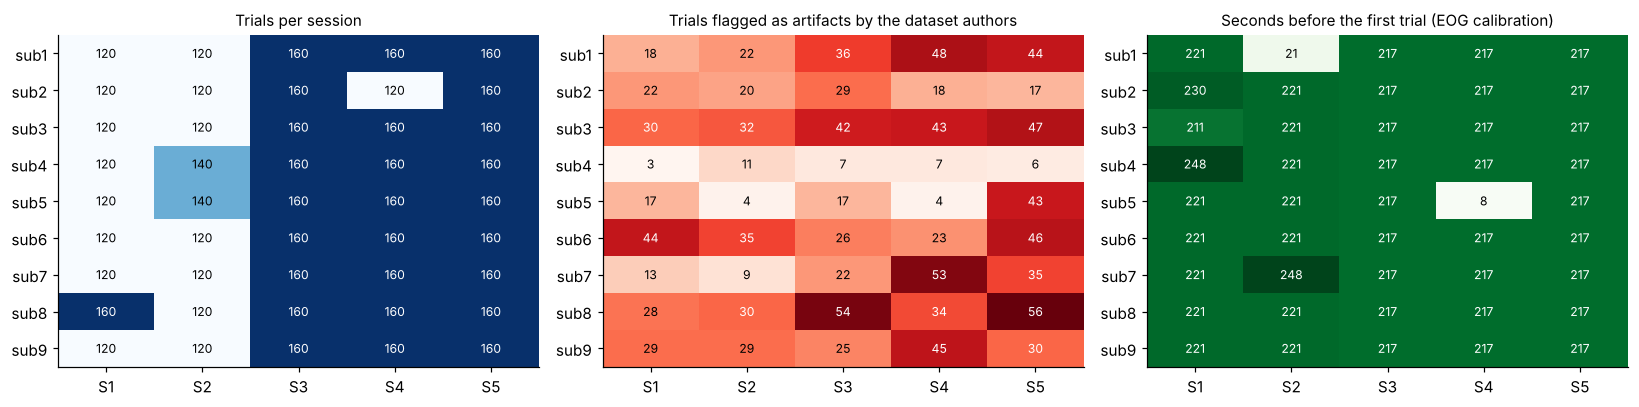

Expert-flagged trials: 1253 of 6520 (19.2 %)


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, title, cmap, fmt) in zip(axes, [("trials", "Trials per session", "Blues", "{:.0f}"),
                                              ("expert_flagged", "Trials flagged as artifacts by the dataset authors", "Reds", "{:.0f}"),
                                              ("first_trial_s", "Seconds before the first trial (EOG calibration)", "Greens", "{:.0f}")]):
    M = audit.pivot(index="subject", columns="session", values=col)
    im = ax.imshow(M.values, cmap=cmap, aspect="auto")
    mid = (np.nanmax(M.values) + np.nanmin(M.values)) / 2
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M.values[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if M.values[i, j] > mid else "black")
    ax.set_xticks(range(5)); ax.set_xticklabels([f"S{s}" for s in SESSIONS]); ax.set_yticks(range(9))
    ax.set_yticklabels([f"sub{s}" for s in SUBJECTS]); ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()
print(f"Expert-flagged trials: {audit.expert_flagged.sum()} of {audit.trials.sum()} "
      f"({100 * audit.expert_flagged.sum() / audit.trials.sum():.1f} %)")

## 4. Where the signal comes from
Each EEG channel is a **bipolar pair** of electrodes ~2.5 cm apart around C3, Cz or C4; the channel is their difference, so it
mainly sees cortex right under the pair. C3 and C4 lie over the left and right **hand area of the primary motor cortex**
(precentral gyrus). Each hand is controlled by the opposite hemisphere, so imagining the right hand should reduce mu/beta power at
C3, and the left hand at C4.

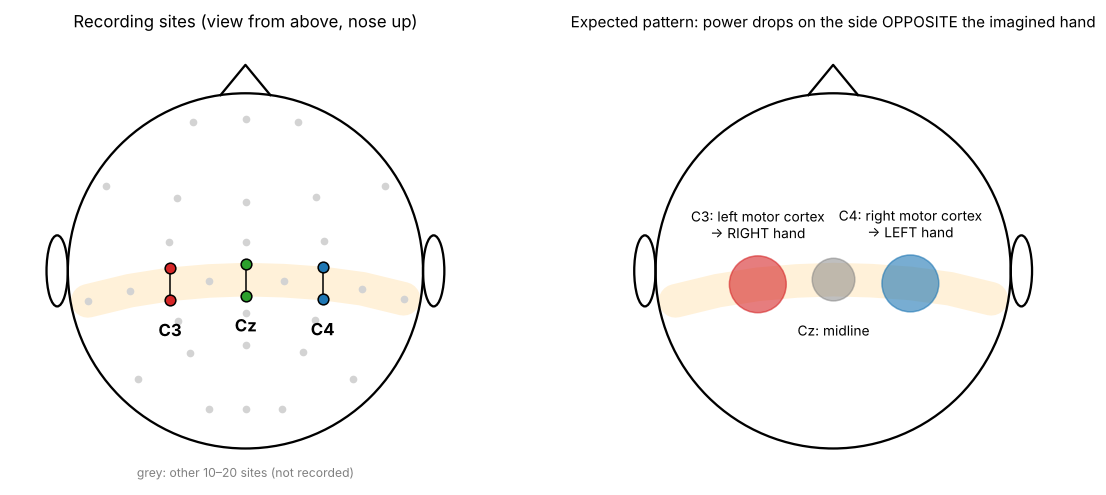

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
draw_head(axes[0])
for ch, color in zip(CH_EEG, ["C3", "C2", "C0"]):
    x, y = head_xy(ch)
    axes[0].plot([x, x], [y - 0.045, y + 0.045], color="k", lw=1, zorder=2)
    axes[0].plot([x, x], [y - 0.045, y + 0.045], "o", color=color, ms=7, mec="k", zorder=3)
    axes[0].text(x, y - 0.1, ch, ha="center", va="top", fontsize=11, weight="bold")
axes[0].text(0, -0.58, "grey: other 10–20 sites (not recorded)", ha="center", fontsize=8, color="grey")
axes[0].set_title("Recording sites (view from above, nose up)", fontsize=11)
draw_head(axes[1], grid=False)
for ch, txt, col in [("C3", "C3: left motor cortex\n→ RIGHT hand", "C3"), ("C4", "C4: right motor cortex\n→ LEFT hand", "C0")]:
    x, y = head_xy(ch)
    axes[1].add_patch(Circle((x, y), 0.08, color=col, alpha=0.6, zorder=3))
    axes[1].text(x, y + 0.13, txt, ha="center", fontsize=9)
x, y = head_xy("Cz"); axes[1].add_patch(Circle((x, y), 0.06, color="grey", alpha=0.5, zorder=3))
axes[1].text(x, y - 0.12, "Cz: midline", ha="center", va="top", fontsize=9)
axes[1].set_title("Expected pattern: power drops on the side OPPOSITE the imagined hand", fontsize=10)
plt.tight_layout(); plt.show()

### The same in 3-D
Electrodes (squares) at their template positions and the hand area of the primary motor cortex underneath (circles), drawn on
a transparent MNI brain with **nilearn**. Positions are approximate: electrode coordinates come from MNE's standard 10–20
template, and the hand-area coordinates (±37, −21, 58 mm) are the centre of M1 in the Human Motor Area Template
(Mayka et al., 2006).

**What this does not show:** with three bipolar channels we cannot estimate where in the brain a signal is generated (source
localisation needs dozens of electrodes and a head model). The picture shows what each electrode sits over, not a source estimate.

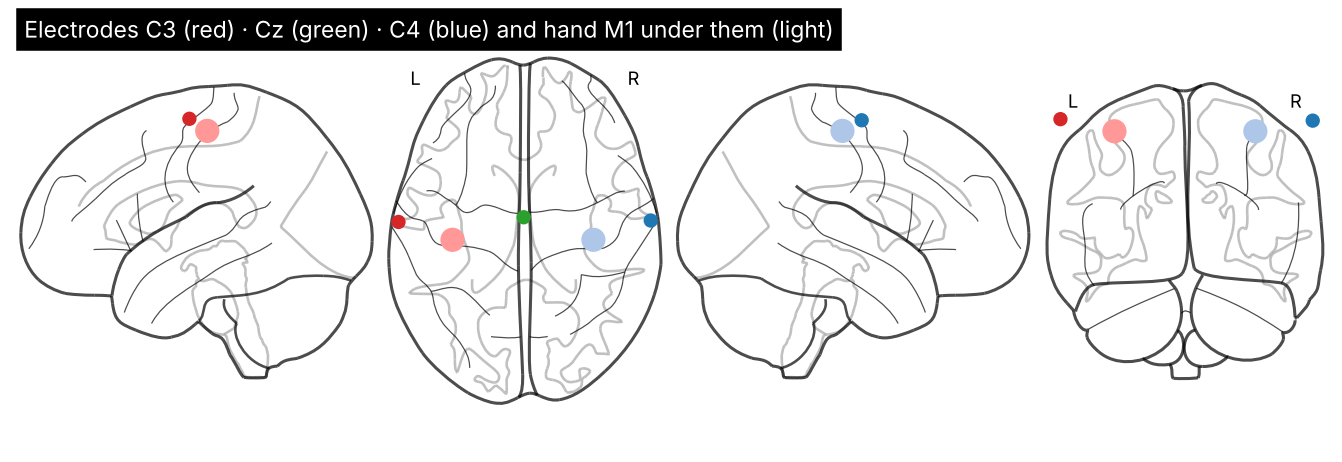

In [9]:
from nilearn import plotting

scalp = {ch: np.array(_POS3D[ch]) * 1000 for ch in CH_EEG}               # mm, template head coordinates
cortex = {"left hand M1": np.array([-37, -21, 58]), "right hand M1": np.array([37, -21, 58])}
coords = np.vstack([*scalp.values(), *cortex.values()])
colors = ["#d62728", "#2ca02c", "#1f77b4", "#ff9896", "#aec7e8"]      # C3 red, Cz green, C4 blue; M1 in lighter shades
fig = plt.figure(figsize=(12, 4))
plotting.plot_connectome(np.zeros((5, 5)), coords, node_color=colors, node_size=[70, 70, 70, 220, 220],
                         display_mode="lzry", figure=fig, colorbar=False,
                         title="Electrodes C3 (red) · Cz (green) · C4 (blue) and hand M1 under them (light)")
plt.show()

view = plotting.view_markers(coords, marker_color=colors, marker_size=[9, 9, 9, 12, 12],
                             marker_labels=CH_EEG + list(cortex))
view          # interactive: drag to rotate (works in Jupyter / Colab)

### Trial timeline and analysis windows
Both session types show the cue at ~3 s (confirmed from the data in study v1 and again in Section 7).

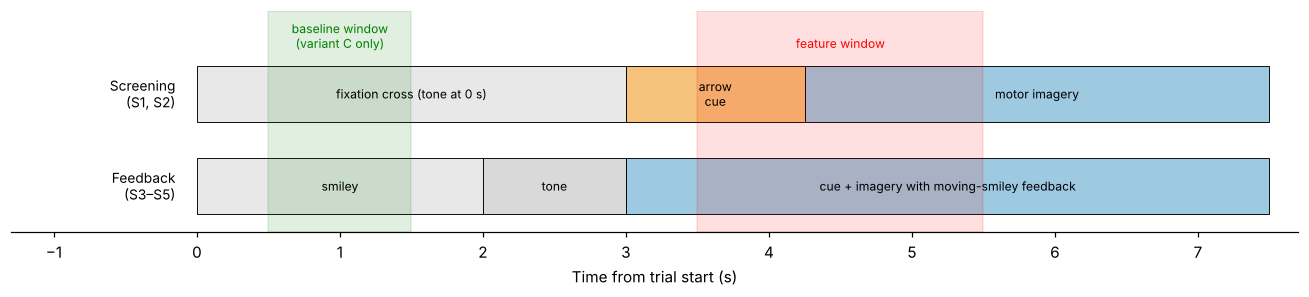

In [10]:
fig, ax = plt.subplots(figsize=(12, 2.8))
rows_tl = [("Screening\n(S1, S2)", [(0, 3, "fixation cross (tone at 0 s)", "#e8e8e8"), (3, 4.25, "arrow\ncue", "#f4c27a"),
                                     (4.25, 7.5, "motor imagery", "#9ecae1")]),
           ("Feedback\n(S3–S5)", [(0, 2, "smiley", "#e8e8e8"), (2, 3, "tone", "#d9d9d9"),
                                   (3, 7.5, "cue + imagery with moving-smiley feedback", "#9ecae1")])]
for r, (label, segs) in enumerate(rows_tl):
    yb = 1.2 - r * 1.0
    for a, b, txt, col in segs:
        ax.add_patch(Rectangle((a, yb), b - a, 0.6, fc=col, ec="k", lw=0.6))
        ax.text((a + b) / 2, yb + 0.3, txt, ha="center", va="center", fontsize=8)
    ax.text(-0.15, yb + 0.3, label, ha="right", va="center", fontsize=9)
for (a, b), col, txt in [(BASE_WIN, "green", "baseline window\n(variant C only)"), (FEAT_WIN, "red", "feature window")]:
    ax.axvspan(a, b, color=col, alpha=0.12); ax.text((a + b) / 2, 2.0, txt, ha="center", fontsize=8, color=col)
ax.set_xlim(-1.3, 7.7); ax.set_ylim(0, 2.4); ax.set_yticks([]); ax.set_xlabel("Time from trial start (s)")
for sp in ["left", "top", "right"]:
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

## 5. Preprocessing
For every session (same steps for all sessions and both arms):
1. **Units and MNE object.** The files store µV; MNE works in volts.
2. **FIR band-pass 1–40 Hz** (zero-phase) on the continuous signal: removes slow drift; keeps everything up to the highest band edge
   (30 Hz). The 50 Hz line noise was already notched by the amplifier.
3. **EOG regression** (notebook 04). We estimate how much of each EOG channel leaks into each EEG channel **from the pre-trial
   calibration recording**, where the person moved the eyes on purpose, and subtract that leak from the whole session. Using a
   separate recording is cleaner than fitting on the task data, and it uses no class labels. Sessions without ≥ 60 s of
   calibration fall back to fitting on the whole session (also label-free); the table below lists which.

The channels are bipolar (already referenced), so we tell MNE not to re-reference them.

In [11]:
def to_raw(d):
    info = mne.create_info(CH_EEG + CH_EOG, d["fs"], ["eeg"] * 3 + ["eog"] * 3)
    assert not np.isnan(d["X"]).any(), "missing samples found — interpolate before filtering"
    raw = mne.io.RawArray(d["X"].T * 1e-6, info)
    raw.set_eeg_reference(ref_channels=[])
    return raw

def preprocess(d, eog_regression=True):
    raw = to_raw(d)
    raw.filter(L_FREQ, H_FREQ, picks="all", fir_design="firwin")
    info = {"eog_fit_on": "none", "coef": np.full((3, 3), np.nan)}
    if eog_regression:
        calib_end = d["onsets"][0] / d["fs"] - 2.0
        if calib_end >= MIN_CALIB_S:
            fit_raw, info["eog_fit_on"] = raw.copy().crop(0, calib_end), f"calibration ({calib_end:.0f} s)"
        else:
            fit_raw, info["eog_fit_on"] = raw, "whole session (no calibration)"
        model = EOGRegression(picks="eeg", picks_artifact="eog", proj=False).fit(fit_raw)
        raw = model.apply(raw)
        info["coef"] = model.coef_
    return raw, info

### What EOG regression does
The pre-trial calibration recording of subject 1, session 1: raw signal, after the filter, and after regression. Eye movements
(orange) leak into the EEG channels; regression subtracts the leak.

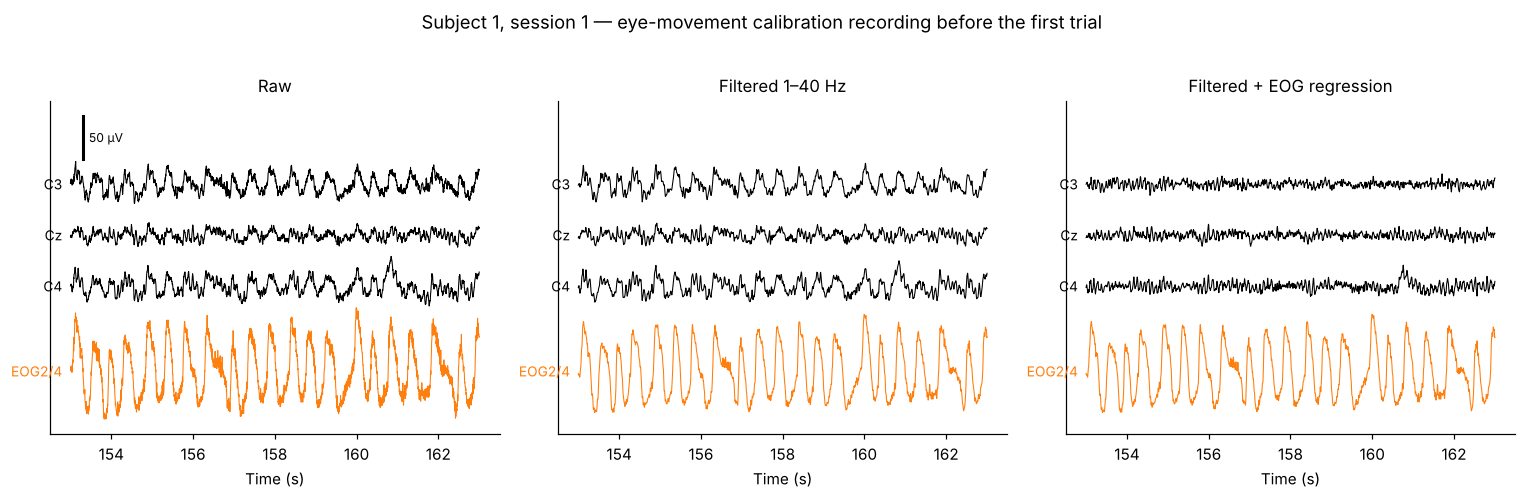

In [12]:
d_demo = data[1][1]
raw_unf = to_raw(d_demo)
raw_f, _ = preprocess(d_demo, eog_regression=False)
raw_r, info_demo = preprocess(d_demo, eog_regression=True)
eog2 = raw_f.get_data(picks="EOG2")[0] * 1e6
fs_ = d_demo["fs"]; calib_n = int(d_demo["onsets"][0] - 2 * fs_); win = int(10 * fs_)
best_score, t0_ = -1, 0.0
for a in range(0, calib_n - win, int(fs_)):                    # 10-s windows in 1-s steps
    seg = eog2[a:a + win]
    flat = np.convolve((np.abs(np.diff(seg)) < 1e-3).astype(float), np.ones(25), "valid").max() >= 25
    if flat or np.abs(seg - seg.mean()).max() > 400:            # skip amplifier clipping / saturation
        continue
    if seg.std() > best_score:
        best_score, t0_ = seg.std(), a / fs_
t1_ = t0_ + 10
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, (title, r) in zip(axes, [("Raw", raw_unf), ("Filtered 1–40 Hz", raw_f), ("Filtered + EOG regression", raw_r)]):
    seg = r.copy().crop(t0_, t1_); tt = seg.times + t0_
    for k, ch in enumerate(CH_EEG):
        x = seg.get_data(picks=ch)[0] * 1e6
        ax.plot(tt, x - x.mean() - k * 60, lw=0.7, color="k"); ax.text(tt[0] - 0.2, -k * 60, ch, ha="right", va="center", fontsize=9)
    e = seg.get_data(picks="EOG2")[0] * 1e6
    ax.plot(tt, (e - e.mean()) / 4 - 220, lw=0.7, color="C1"); ax.text(tt[0] - 0.2, -220, "EOG2/4", ha="right", va="center", fontsize=9, color="C1")
    ax.set_title(title, fontsize=11); ax.set_xlabel("Time (s)"); ax.set_yticks([])
axes[0].plot([t0_ + 0.3] * 2, [30, 80], color="k", lw=2); axes[0].text(t0_ + 0.45, 55, "50 µV", fontsize=8, va="center")
plt.suptitle("Subject 1, session 1 — eye-movement calibration recording before the first trial", y=1.02)
plt.tight_layout(); plt.show()

## 6. Epochs, features and trial cleaning
We process one session at a time and keep only what the analysis needs:
- **Welch PSD** (1 Hz resolution) in the feature window 3.5–5.5 s, for both preprocessing versions (with and without EOG regression);
- Welch PSD in the pre-cue baseline window 0.5–1.5 s (used only by fix C, baseline-relative power);
- the run (block) each trial belongs to: runs of 20 trials in screening sessions and 40 in feedback sessions, in recording order;
- **band-power time courses** (Hilbert envelope of narrow bands) for the ERD and time–frequency figures;
- per-trial log-variance for outlier detection.

**Cleaning rule — applied only to trials used for training.** A trial is left out of training if (a) the dataset authors flagged it
as an artifact, or (b) its EEG log-variance is more than 5 robust SDs (median ± 5 × 1.4826 × MAD) from the session median on any
channel. This applies to the training session in cross-session tests **and** to the training folds of within-session
cross-validation. **Scored trials are never removed**: an online BCI must classify every trial, and both comparisons are scored
on exactly the same trials.

In [13]:
TF_BANDS = [(lo, lo + 4) for lo in range(6, 31, 2)]            # 4-Hz bands, centres 8–32 Hz, for time–frequency maps
ERD_BANDS = {"mu 8–12": (8, 12), "beta 13–30": (13, 30)}
DS = 10                                                          # envelope downsampling: 250 Hz -> 25 Hz
N_EP = int(EPOCH_LEN * 250) + 1

def envelope_power(raw_eeg_data, band, fs, onsets):
    x = mne.filter.filter_data(raw_eeg_data, fs, band[0], band[1], fir_design="firwin", verbose=False)
    n = x.shape[-1]
    p = np.abs(hilbert(x, N=next_fast_len(n), axis=-1)[..., :n]) ** 2
    idx = onsets[:, None] + np.arange(N_EP)[None, :]
    ep = p[:, idx].transpose(1, 0, 2)                            # trials, channels, time
    return ep[:, :, : (N_EP // DS) * DS].reshape(len(onsets), 3, -1, DS).mean(-1)

def window_psd(ep, fs, win):
    a, b = int(win[0] * fs), int(win[1] * fs) + 1
    psd, f = psd_array_welch(ep[:, :, a:b], fs, fmin=1, fmax=40, n_fft=250, n_per_seg=250, n_overlap=125, verbose=False)
    return psd, f

def signed_r2(L, y):
    """Signed r² between a feature array (trials, ...) and the label (right = 1)."""
    Lc = L - L.mean(0); yc = (y - y.mean()).reshape((-1,) + (1,) * (L.ndim - 1))
    r = (Lc * yc).sum(0) / np.sqrt((Lc ** 2).sum(0) * (yc ** 2).sum())
    return np.sign(r) * r ** 2

S = {}           # S[(subj, sess)] -> per-session results
eog_rows = []
t0 = time.time()
for subj in SUBJECTS:
    for s in SESSIONS:
        d = data[subj][s]; fs = d["fs"]; on = d["onsets"]
        rec = {"y": d["y"], "expert": d["artifacts"], "block": np.arange(len(d["y"])) // RUN_LEN[SESS_TYPE[s]]}
        gaps = np.diff(on) / fs
        if SESS_TYPE[s] == "feedback":               # runs are separated by ~23-s pauses: check the reconstruction
            big = set(np.where(gaps > 2 * np.median(gaps))[0])
            assert big == set(np.where(np.diff(rec["block"]) == 1)[0]), f"run reconstruction mismatch sub{subj} S{s}"
        for version, use_eog in [("eog", True), ("noeog", False)]:
            raw, info = preprocess(d, eog_regression=use_eog)
            eeg = raw.get_data(picks="eeg")
            ep = eeg[:, on[:, None] + np.arange(N_EP)[None, :]].transpose(1, 0, 2) * 1e6     # µV, trials × ch × time
            rec[f"psd_{version}"], freqs = window_psd(ep, fs, FEAT_WIN)
            rec[f"logvar_{version}"] = np.log(ep.var(-1))
            rec[f"psdbase_{version}"], _ = window_psd(ep, fs, BASE_WIN)
            if use_eog:
                rec["logvar"] = rec["logvar_eog"]
                rec["tf_r2"] = np.stack([signed_r2(np.log(envelope_power(eeg, b, fs, on)), d["y"]) for b in TF_BANDS])
                rec["erd"] = {k: envelope_power(eeg, b, fs, on) for k, b in ERD_BANDS.items()}
                eog_rows.append(dict(subject=subj, session=s, eog_fit_on=info["eog_fit_on"],
                                     leak=float(np.abs(info["coef"]).sum(1).mean())))
                if (subj, s) == (1, 1):
                    demo_epochs = ep
        for version in ("eog", "noeog"):
            lv = rec[f"logvar_{version}"]
            med, mad = np.median(lv, 0), 1.4826 * np.median(np.abs(lv - np.median(lv, 0)), 0)
            rec[f"outlier_{version}"] = (np.abs(lv - med) / mad > ROBUST_Z).any(1)
            rec[f"keep_{version}"] = ~(rec["expert"] | rec[f"outlier_{version}"])
        rec["outlier"], rec["keep"] = rec["outlier_eog"], rec["keep_eog"]
        S[(subj, s)] = rec
FREQS = freqs
TF_TIMES = (np.arange(N_EP // DS) * DS + DS / 2) / 250
print(f"Processed 45 sessions in {time.time() - t0:.0f} s; PSD frequencies {FREQS[0]:.0f}–{FREQS[-1]:.0f} Hz, step {FREQS[1]-FREQS[0]:.0f} Hz")

Processed 45 sessions in 103 s; PSD frequencies 1–40 Hz, step 1 Hz


EOG regression fitted on:


,sessions
eog_fit_on,
calibration,43
whole session (no calibration),2


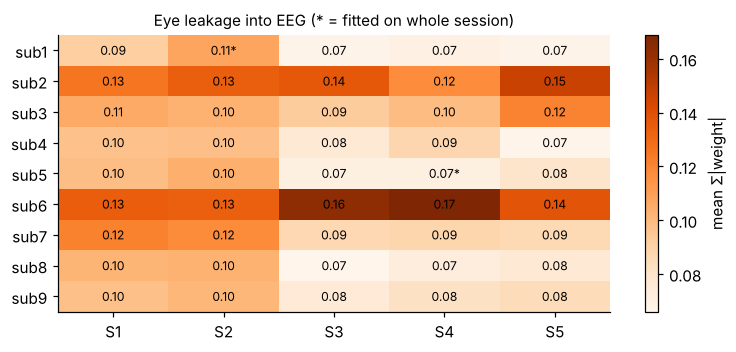

In [14]:
eog_tab = pd.DataFrame(eog_rows)
print("EOG regression fitted on:")
display(eog_tab.eog_fit_on.str.replace(r" \(\d+ s\)", "", regex=True).value_counts().to_frame("sessions"))
fig, ax = plt.subplots(figsize=(7, 3.3))
M = eog_tab.pivot(index="subject", columns="session", values="leak")
im = ax.imshow(M.values, cmap="Oranges", aspect="auto")
for i in range(9):
    for j in range(5):
        fit = eog_tab[(eog_tab.subject == i + 1) & (eog_tab.session == j + 1)].eog_fit_on.iloc[0]
        ax.text(j, i, f"{M.values[i, j]:.2f}" + ("*" if fit.startswith("whole") else ""), ha="center", va="center", fontsize=8)
ax.set_xticks(range(5)); ax.set_xticklabels([f"S{s}" for s in SESSIONS]); ax.set_yticks(range(9))
ax.set_yticklabels([f"sub{s}" for s in SUBJECTS]); plt.colorbar(im, ax=ax, label="mean Σ|weight|")
ax.set_title("Eye leakage into EEG (* = fitted on whole session)", fontsize=10); plt.tight_layout(); plt.show()

### Trial cleaning results

Over all sessions: 1272 of 6520 trials would be left out of training (19.5 %): 1253 expert-flagged, 19 extra variance outliers. All trials are still scored.
Runs (blocks) per session:


session,1,2,3,4,5
subject,,,,,
1,6,6,4,4,4
2,6,6,4,3,4
3,6,6,4,4,4
4,6,7,4,4,4
5,6,7,4,4,4
6,6,6,4,4,4
7,6,6,4,4,4
8,8,6,4,4,4
9,6,6,4,4,4


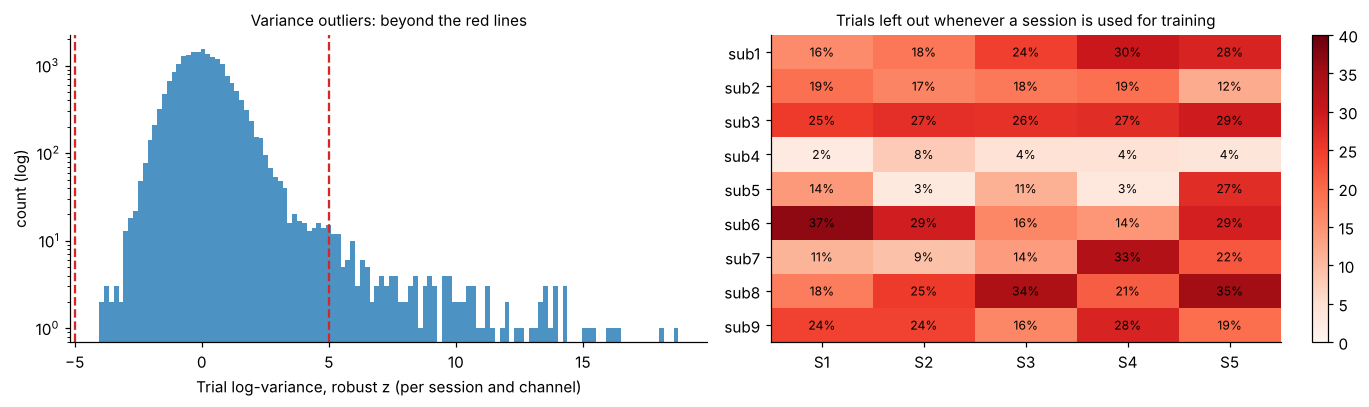

In [15]:
clean_rows = []
for (subj, s), r in S.items():
    clean_rows.append(dict(subject=subj, session=s, trials=len(r["y"]), blocks=int(r["block"].max() + 1),
                           expert=int(r["expert"].sum()), outlier=int(r["outlier"].sum()),
                           outlier_only=int((r["outlier"] & ~r["expert"]).sum()), removed=int((~r["keep"]).sum())))
cleaning = pd.DataFrame(clean_rows)
tr = cleaning
print(f"Over all sessions: {tr.removed.sum()} of {tr.trials.sum()} trials would be left out of training "
      f"({100 * tr.removed.sum() / tr.trials.sum():.1f} %): {tr.expert.sum()} expert-flagged, {tr.outlier_only.sum()} extra variance "
      f"outliers. All trials are still scored.")
print("Runs (blocks) per session:"); display(cleaning.pivot(index="subject", columns="session", values="blocks"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
lv_all = np.concatenate([(r["logvar"] - np.median(r["logvar"], 0)) /
                         (1.4826 * np.median(np.abs(r["logvar"] - np.median(r["logvar"], 0)), 0)) for r in S.values()])
axes[0].hist(lv_all.ravel(), bins=120, color="C0", alpha=0.8, log=True)
for v in (-ROBUST_Z, ROBUST_Z):
    axes[0].axvline(v, color="C3", ls="--")
axes[0].set_xlabel("Trial log-variance, robust z (per session and channel)"); axes[0].set_ylabel("count (log)")
axes[0].set_title("Variance outliers: beyond the red lines", fontsize=10)
M = cleaning.assign(pct=100 * cleaning.removed / cleaning.trials).pivot(index="subject", columns="session", values="pct")
im = axes[1].imshow(M.values, cmap="Reds", aspect="auto", vmin=0, vmax=40)
for i in range(9):
    for j in range(5):
        axes[1].text(j, i, f"{M.values[i, j]:.0f}%", ha="center", va="center", fontsize=8)
axes[1].set_xticks(range(5)); axes[1].set_xticklabels([f"S{s}" for s in SESSIONS])
axes[1].set_yticks(range(9)); axes[1].set_yticklabels([f"sub{s}" for s in SUBJECTS])
axes[1].set_title("Trials left out whenever a session is used for training", fontsize=10)
plt.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

### A flagged trial next to a clean one
Subject 1, session 1: the first expert-flagged trial and the first clean trial of the same class.

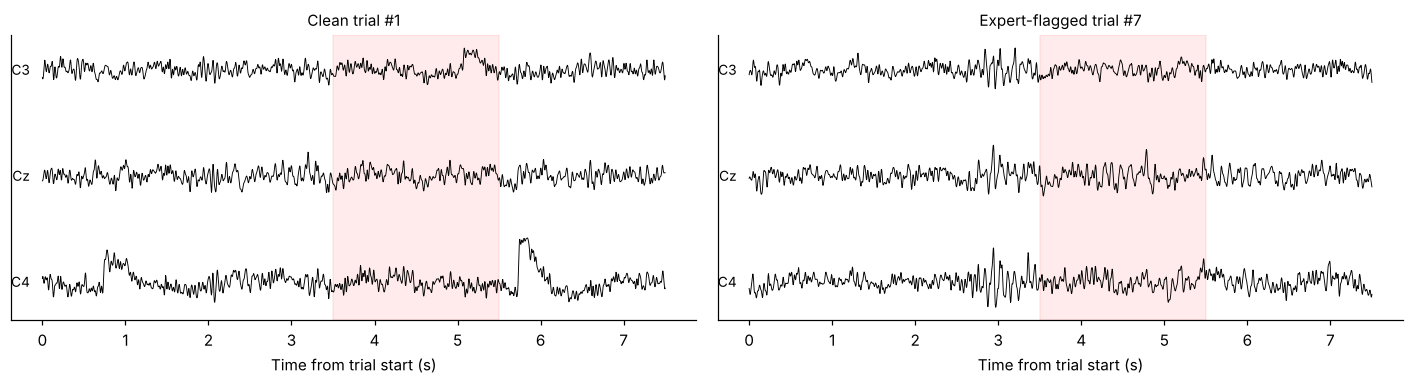

In [16]:
r1 = S[(1, 1)]
i_bad = int(np.where(r1["expert"])[0][0])
i_ok = int(np.where(~r1["expert"] & ~r1["outlier"] & (r1["y"] == r1["y"][i_bad]))[0][0])
tt = np.arange(N_EP) / 250
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, i, title in [(axes[0], i_ok, f"Clean trial #{i_ok}"), (axes[1], i_bad, f"Expert-flagged trial #{i_bad}")]:
    for k, ch in enumerate(CH_EEG):
        ax.plot(tt, demo_epochs[i, k] - k * 50, lw=0.6, color="k"); ax.text(-0.15, -k * 50, ch, ha="right", va="center", fontsize=9)
    ax.axvspan(*FEAT_WIN, color="red", alpha=0.08); ax.set_title(title, fontsize=10); ax.set_xlabel("Time from trial start (s)")
    ax.set_yticks([])
plt.tight_layout(); plt.show()

## 7. Is the expected brain response there? (before decoding anything)
ERD = % change of band power relative to the pre-cue period, averaged over trials first and then expressed as % (the classic
definition). Screening sessions (S1–S2) and feedback sessions (S3–S5) are shown separately.

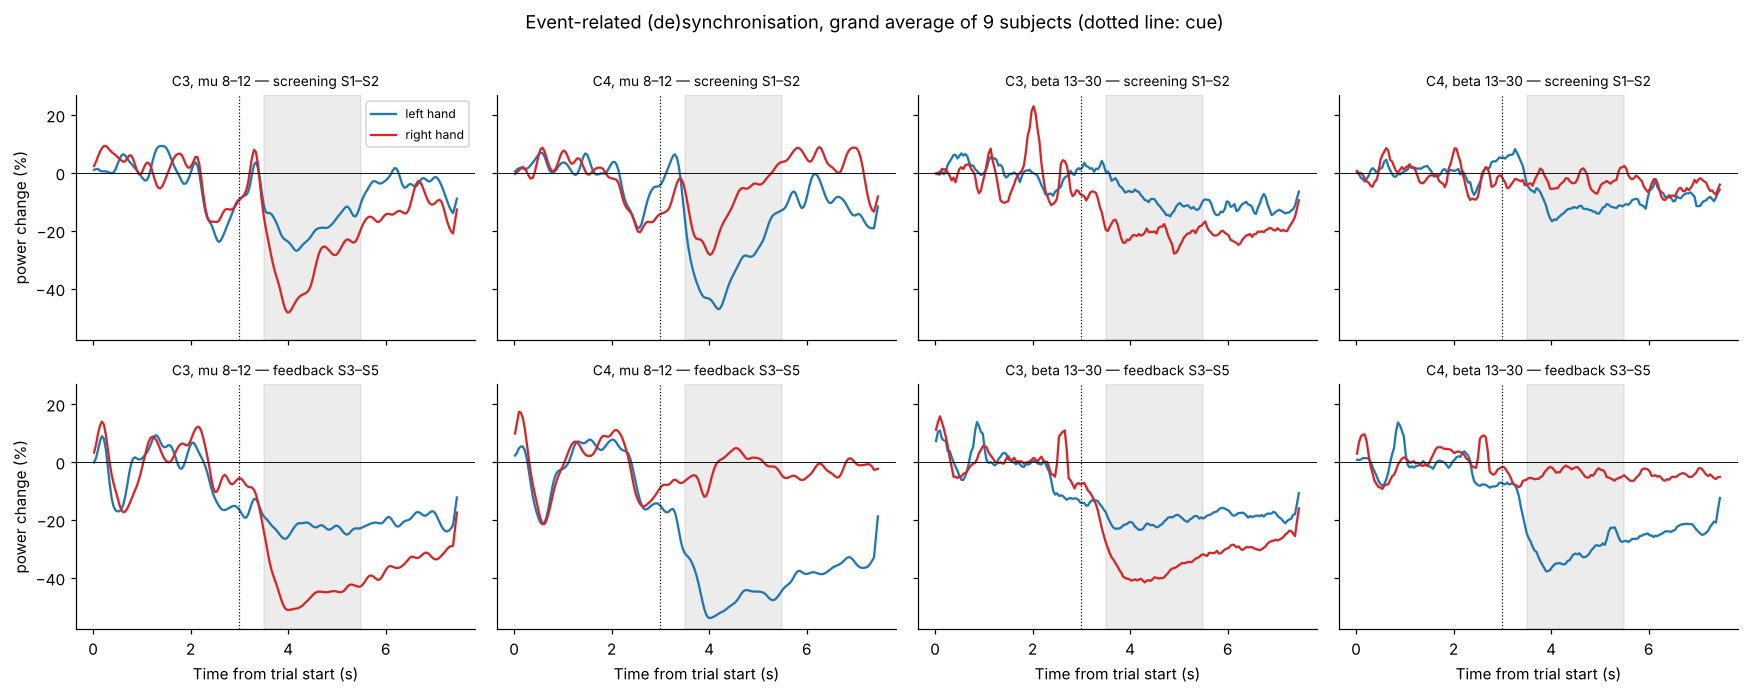

In [17]:
def erd_curve(p, y, cls, base=(0.5, 2.5)):
    m = p[y == cls].mean(0)
    b = m[:, (TF_TIMES >= base[0]) & (TF_TIMES <= base[1])].mean(-1, keepdims=True)
    return 100 * (m / b - 1)

def smooth(x, k=5):
    return np.apply_along_axis(lambda v: np.convolve(v, np.ones(k) / k, mode="same"), -1, x)

fig, axes = plt.subplots(2, 4, figsize=(16, 6.2), sharex=True, sharey=True)
for row, sess_set, name in [(0, [1, 2], "screening S1–S2"), (1, [3, 4, 5], "feedback S3–S5")]:
    for col, (band, ch) in enumerate([(b, c) for b in ERD_BANDS for c in ("C3", "C4")]):
        ax = axes[row, col]; ci = CH_EEG.index(ch)
        for cls, lab, colr in [(0, "left hand", "C0"), (1, "right hand", "C3")]:
            curves = [erd_curve(S[(subj, s)]["erd"][band], S[(subj, s)]["y"], cls)[ci] for subj in SUBJECTS for s in sess_set]
            ax.plot(TF_TIMES, smooth(np.mean(curves, 0)), color=colr, label=lab)
        ax.axhline(0, color="k", lw=0.6); ax.axvspan(*FEAT_WIN, color="grey", alpha=0.15); ax.axvline(3, color="k", ls=":", lw=0.8)
        ax.set_title(f"{ch}, {band} — {name}", fontsize=9)
axes[0, 0].legend(fontsize=8); axes[0, 0].set_ylabel("power change (%)"); axes[1, 0].set_ylabel("power change (%)")
for ax in axes[1]:
    ax.set_xlabel("Time from trial start (s)")
plt.suptitle("Event-related (de)synchronisation, grand average of 9 subjects (dotted line: cue)", y=1.01)
plt.tight_layout(); plt.show()

**What to look for:** after the cue (~3 s) power drops more at C3 for the right hand and more at C4 for the left hand, in both bands.
The grey feature window should sit inside that drop.

### Time–frequency view: which frequencies separate the classes, and when?
Signed r² between band power and the class (right = +1), per 4-Hz band and time point. Blue at C3 / red at C4 means the
expected contralateral ERD. All sessions, averaged over subjects.

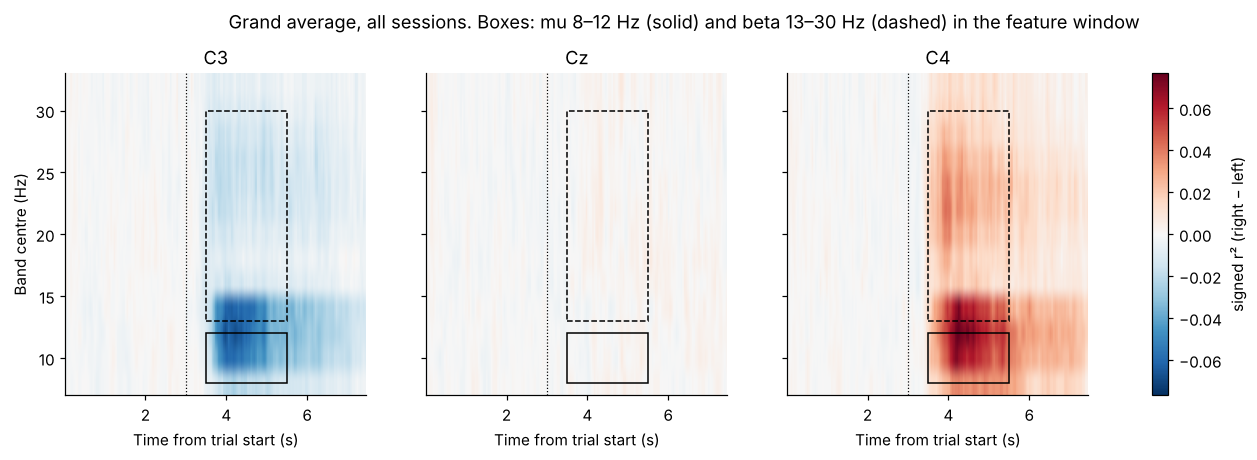

In [18]:
tf_train = np.mean([S[(subj, s)]["tf_r2"] for subj in SUBJECTS for s in SESSIONS], 0)        # bands × ch × time
centres = [np.mean(b) for b in TF_BANDS]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
lim = np.abs(tf_train).max()
for ax, ch in zip(axes, CH_EEG):
    im = ax.imshow(tf_train[:, CH_EEG.index(ch)], aspect="auto", origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim,
                   extent=[TF_TIMES[0], TF_TIMES[-1], centres[0] - 1, centres[-1] + 1])
    ax.axvline(3, color="k", ls=":", lw=0.8); ax.add_patch(Rectangle((FEAT_WIN[0], 8), FEAT_WIN[1] - FEAT_WIN[0], 4, fill=False, ec="k", lw=1))
    ax.add_patch(Rectangle((FEAT_WIN[0], 13), FEAT_WIN[1] - FEAT_WIN[0], 17, fill=False, ec="k", lw=1, ls="--"))
    ax.set_title(ch); ax.set_xlabel("Time from trial start (s)")
axes[0].set_ylabel("Band centre (Hz)"); plt.colorbar(im, ax=axes, label="signed r² (right − left)")
plt.suptitle("Grand average, all sessions. Boxes: mu 8–12 Hz (solid) and beta 13–30 Hz (dashed) in the feature window", y=1.03)
plt.show()

## 8. Features and the three variants
**Log band power:** mean Welch PSD over 1-Hz bins 8–12 Hz (mu) and 13–30 Hz (beta) at C3, Cz and C4, natural log → 6 features.

| Variant | What changes | Idea |
|---|---|---|
| **A** raw log power | — | the standard pipeline |
| **C** baseline-relative | each trial's log power in 3.5–5.5 s **minus** its own log power in 0.5–1.5 s | cancels a day-specific overall power level |
| **D** session z-scored | each feature standardised with the mean and SD of **all trials of its own session** (no labels) | re-centres every day; the team's README hypothesis |

D needs unlabelled data from the new day before decoding it. Sensitivity (c) uses only the new day's first run for this (the
training day is always normalised with all its trials), and scores the remaining runs — the realistic online version.

In [19]:
def logbp(psd, bands=BANDS):
    return np.concatenate([np.log(psd[:, :, (FREQS >= lo) & (FREQS < hi)].mean(-1)) for lo, hi in bands], axis=1)

def features(subj, s, variant="A", version="eog", zmask=None):
    r = S[(subj, s)]
    X = logbp(r[f"psd_{version}"])
    if variant == "C":
        X = X - logbp(r[f"psdbase_{version}"])
    elif variant == "D":
        m = np.ones(len(X), bool) if zmask is None else zmask(r)
        X = (X - X[m].mean(0)) / X[m].std(0)
    return X

def make_clf():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000))

def fast_auc(y, s):
    r = rankdata(s); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

_y = np.r_[np.zeros(50), np.ones(50)].astype(int); _s = np.random.default_rng(0).normal(size=100) + _y * 0.5
assert abs(fast_auc(_y, _s) - roc_auc_score(_y, _s)) < 1e-12
assert logbp(S[(1, 1)]["psd_eog"]).shape[1] == 6
assert (FREQS[(FREQS >= 8) & (FREQS < 13)] == np.arange(8, 13)).all() and (FREQS[(FREQS >= 13) & (FREQS < 31)] == np.arange(13, 31)).all()
print("Bands use bins", FREQS[(FREQS >= 8) & (FREQS < 13)].astype(int), "and 13…30 Hz")

Bands use bins [ 8  9 10 11 12] and 13…30 Hz


## 9. Drift you can see before decoding anything
### (i) Does the overall power level move between days?
Mean log mu power (C3 and C4) in each session, relative to session 1 — one line per subject. No labels, no decoder.

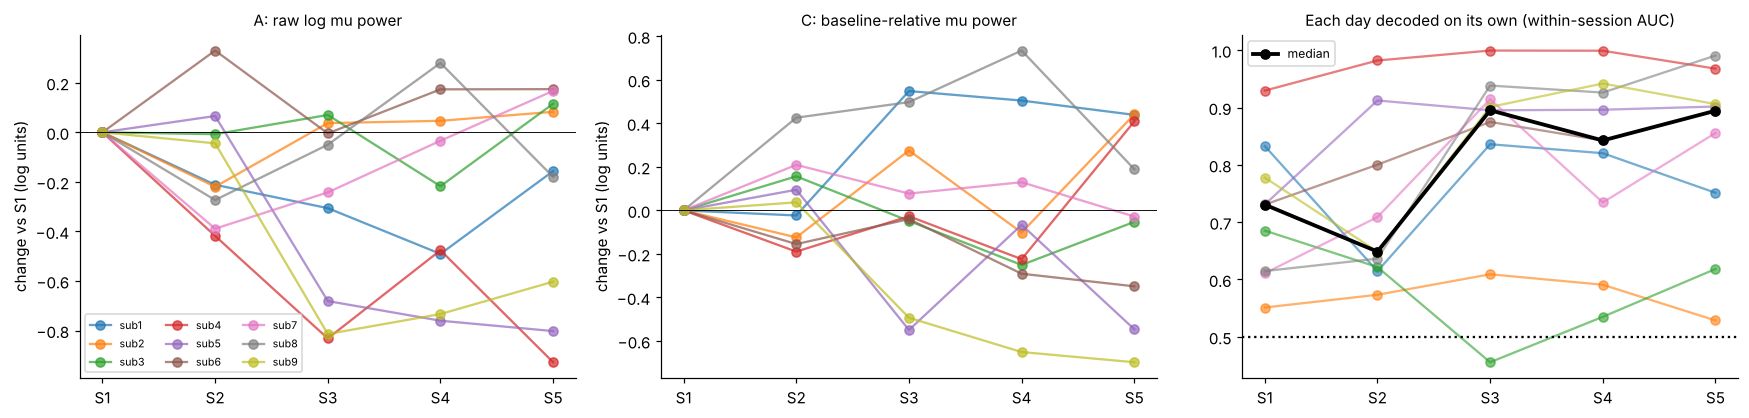

Median within-session AUC per session: {1: 0.731, 2: 0.649, 3: 0.895, 4: 0.842, 5: 0.894}


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
for ax, (variant, title) in zip(axes[:2], [("A", "A: raw log mu power"), ("C", "C: baseline-relative mu power")]):
    for subj in SUBJECTS:
        m = np.array([features(subj, s, variant)[:, [0, 2]].mean() for s in SESSIONS])
        ax.plot([f"S{s}" for s in SESSIONS], m - m[0], marker="o", alpha=0.7, label=f"sub{subj}")
    ax.axhline(0, color="k", lw=0.6); ax.set_title(title, fontsize=10); ax.set_ylabel("change vs S1 (log units)")
axes[0].legend(ncol=3, fontsize=7)

# (ii) How well can each day be decoded on its own? Within-session block CV, all training trials, variant A.
within_by_sess = pd.DataFrame(index=SUBJECTS, columns=SESSIONS, dtype=float)
for subj in SUBJECTS:
    for s in SESSIONS:
        r = S[(subj, s)]; X = features(subj, s); y = r["y"]; blk = r["block"]; oof = np.zeros(len(y))
        for g in np.unique(blk):
            tr_ = (blk != g) & r["keep_eog"]
            oof[blk == g] = make_clf().fit(X[tr_], y[tr_]).decision_function(X[blk == g])
        within_by_sess.loc[subj, s] = fast_auc(y, oof)
for subj in SUBJECTS:
    axes[2].plot([f"S{s}" for s in SESSIONS], within_by_sess.loc[subj], marker="o", alpha=0.6)
axes[2].plot([f"S{s}" for s in SESSIONS], within_by_sess.median(), color="k", lw=2.5, marker="o", label="median")
axes[2].axhline(0.5, color="k", ls=":"); axes[2].set_title("Each day decoded on its own (within-session AUC)", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Median within-session AUC per session:", within_by_sess.median().round(3).to_dict())

### (ii) Does the brain pattern move between days?
Grand-average contrast of mu ERD (right-hand minus left-hand imagery) in the feature window, drawn on the head for each session.
A stable pattern is blue at C3 and red at C4 every day.

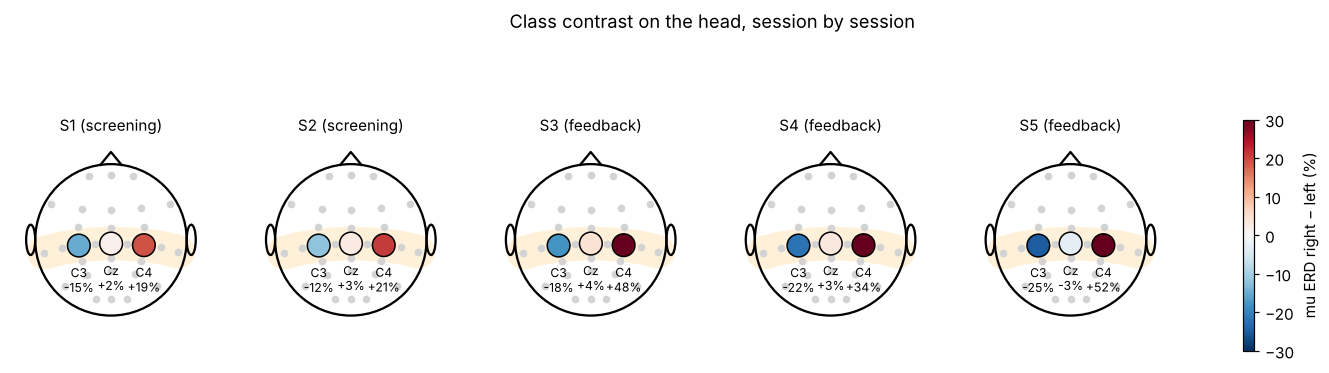

In [21]:
imag_t = (TF_TIMES >= FEAT_WIN[0]) & (TF_TIMES <= FEAT_WIN[1])
fig, axes = plt.subplots(1, 5, figsize=(17, 3.9))
for ax, s in zip(axes, SESSIONS):
    diff = np.mean([erd_curve(S[(subj, s)]["erd"]["mu 8–12"], S[(subj, s)]["y"], 1)[:, imag_t].mean(-1) -
                    erd_curve(S[(subj, s)]["erd"]["mu 8–12"], S[(subj, s)]["y"], 0)[:, imag_t].mean(-1) for subj in SUBJECTS], 0)
    sm = head_values(ax, dict(zip(CH_EEG, diff)), vmin=-30, vmax=30, title=f"S{s} ({SESS_TYPE[s]})")
fig.colorbar(sm, ax=axes, shrink=0.7, label="mu ERD right − left (%)")
plt.suptitle("Class contrast on the head, session by session", y=1.02); plt.show()

### (iii) Does the decoder rely on the same features every day?
A decoder (variant A) fitted separately on each session's cleaned trials. Left: mean weights (positive → "right hand").
Right: cosine similarity between the weight vectors of every pair of days, averaged over subjects (1 = same direction).

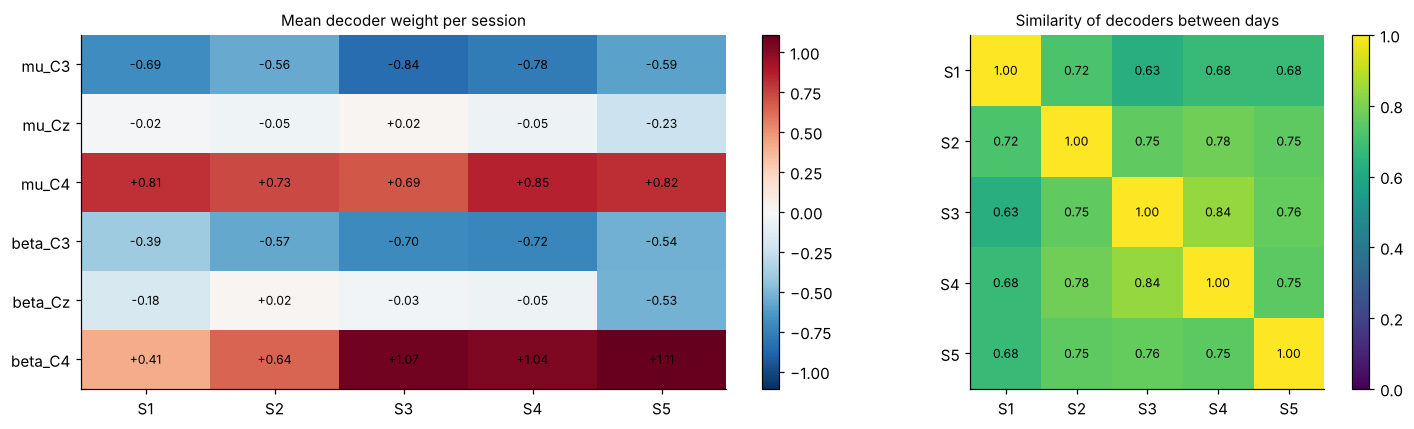

In [22]:
W = np.zeros((len(SUBJECTS), len(SESSIONS), 6))
for i, subj in enumerate(SUBJECTS):
    for j, s in enumerate(SESSIONS):
        r = S[(subj, s)]; k = r["keep_eog"]
        W[i, j] = make_clf().fit(features(subj, s)[k], r["y"][k])[-1].coef_[0]
Wn = W / np.linalg.norm(W, axis=-1, keepdims=True)
COS = np.einsum("isf,itf->ist", Wn, Wn).mean(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.3, 1]})
Wm = W.mean(0).T; lim = np.abs(Wm).max()
im = axes[0].imshow(Wm, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for a in range(6):
    for b in range(5):
        axes[0].text(b, a, f"{Wm[a, b]:+.2f}", ha="center", va="center", fontsize=8)
axes[0].set_yticks(range(6)); axes[0].set_yticklabels(FEATURE_NAMES); axes[0].set_xticks(range(5))
axes[0].set_xticklabels([f"S{s}" for s in SESSIONS]); axes[0].set_title("Mean decoder weight per session", fontsize=10)
plt.colorbar(im, ax=axes[0], fraction=0.046)
im = axes[1].imshow(COS, cmap="viridis", vmin=0, vmax=1)
for a in range(5):
    for b in range(5):
        axes[1].text(b, a, f"{COS[a, b]:.2f}", ha="center", va="center", fontsize=8, color="w" if COS[a, b] < 0.6 else "k")
axes[1].set_xticks(range(5)); axes[1].set_yticks(range(5))
axes[1].set_xticklabels([f"S{s}" for s in SESSIONS]); axes[1].set_yticklabels([f"S{s}" for s in SESSIONS])
axes[1].set_title("Similarity of decoders between days", fontsize=10); plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

## 10. Evaluation (no leakage, same trials scored in both comparisons)
For a training session *a* and a scored session *b*:
- **Within-session:** leave-one-run-out CV inside *b*. Training folds use only cleaned trials; every trial of the held-out run is
  scored.
- **Cross-session:** fit on the cleaned trials of *a*; score every trial of *b*.
- **Same scoring on both sides:** AUC is computed **run by run** on exactly the same trials for both decoders, then averaged over
  runs. (Pooling out-of-fold scores from several fold models into one AUC — the method planned and used in v1 — penalises the
  within side for offset differences between fold models; it is kept as sensitivity analysis (f).)
- **Matched size:** both decoders get the same number of training trials (the smaller of the two), drawn class-stratified at
  random, 20 times; results are averaged.
- Scaler and classifier are refitted inside every fold.

In [23]:
def strat_sub(idx, y, n, rng):
    """n indices from idx keeping the class proportions of y[idx]."""
    yi = y[idx]; classes, counts = np.unique(yi, return_counts=True)
    quota = np.floor(counts / len(yi) * n).astype(int)
    quota[np.argsort(-(counts / len(yi) * n - quota))[: n - quota.sum()]] += 1
    return np.concatenate([rng.choice(idx[yi == c], q, replace=False) for c, q in zip(classes, quota)])

def per_run(fn, y, s, blk, runs):
    vals = [fn(y[blk == g], s[blk == g]) for g in runs if len(np.unique(y[blk == g])) == 2]
    return float(np.mean(vals))

def bacc0(y, s):
    return balanced_accuracy_score(y, (s > 0).astype(int))

def compare(subj, s_tr, s_te, variant="A", version="eog", clean=True, matched=True, first_block=False, n_rep=N_REP,
            train_override=None, shuffle_within=False, pooled=False, seed_offset=0):
    zmask = (lambda r: r["block"] == 0) if first_block else None      # first-run statistics, applied to the scored day only
    rt, re_ = S[(subj, s_tr)] if s_tr else None, S[(subj, s_te)]
    if train_override is None:
        Xtr, ytr = features(subj, s_tr, variant, version), rt["y"]
        keep_tr = rt[f"keep_{version}"] if clean else np.ones(len(ytr), bool)
    else:
        Xtr, ytr, keep_tr = train_override
    Xte, yte, blk = features(subj, s_te, variant, version, zmask), re_["y"], re_["block"]
    keep_te = re_[f"keep_{version}"] if clean else np.ones(len(yte), bool)
    scored = (blk >= 1) if first_block else np.ones(len(yte), bool)
    folds = [g for g in np.unique(blk) if g >= 1 or not first_block]
    tr_w = {g: np.where((blk != g) & keep_te)[0] for g in folds}
    for g in folds:                                                     # V1: a run is never on both sides
        assert not np.isin(np.where(blk == g)[0], tr_w[g]).any()
    n = int(min(min(len(v) for v in tr_w.values()), keep_tr.sum())) if matched else None
    rng = np.random.default_rng([SEED, subj, s_tr, s_te, seed_offset])   # own stream per comparison (and per shuffle in V2)
    reps = n_rep if matched else 1
    idx_tr = np.where(keep_tr)[0]
    out = {k: [] for k in ("within", "cross", "within_bacc", "cross_bacc")}
    cross_scores = np.zeros(len(yte))
    for _ in range(reps):
        oof = np.full(len(yte), np.nan)
        for g in folds:
            idx = tr_w[g] if n is None else strat_sub(tr_w[g], yte, n, rng)
            y_fit = rng.permutation(yte[idx]) if shuffle_within else yte[idx]
            oof[blk == g] = make_clf().fit(Xte[idx], y_fit).decision_function(Xte[blk == g])
        idx = idx_tr if n is None else strat_sub(idx_tr, ytr, n, rng)
        sc = make_clf().fit(Xtr[idx], ytr[idx]).decision_function(Xte)
        cross_scores += sc / reps
        if pooled:                                       # v1 method: one AUC over pooled out-of-fold scores
            m = scored
            out["within"].append(fast_auc(yte[m], oof[m])); out["cross"].append(fast_auc(yte[m], sc[m]))
            out["within_bacc"].append(bacc0(yte[m], oof[m])); out["cross_bacc"].append(bacc0(yte[m], sc[m]))
        else:                                            # main: run by run on the same trials, then averaged
            out["within"].append(per_run(fast_auc, yte, oof, blk, folds)); out["cross"].append(per_run(fast_auc, yte, sc, blk, folds))
            out["within_bacc"].append(per_run(bacc0, yte, oof, blk, folds)); out["cross_bacc"].append(per_run(bacc0, yte, sc, blk, folds))
    res = {k: float(np.mean(v)) for k, v in out.items()}
    res.update(drift=res["within"] - res["cross"], drift_bacc=res["within_bacc"] - res["cross_bacc"], n_train=n,
               scores=cross_scores[scored], y=yte[scored])
    return res

def transfer(subj, name, **kw):
    s_tr, scored = TRANSFERS[name]
    rs = [compare(subj, s_tr, s, **kw) for s in scored]
    out = {k: float(np.mean([r[k] for r in rs])) for k in ("within", "cross", "drift", "within_bacc", "cross_bacc", "drift_bacc")}
    out.update(n_train=" / ".join(str(r["n_train"]) for r in rs), scores=np.concatenate([r["scores"] for r in rs]), y=np.concatenate([r["y"] for r in rs]),
               per_session={s: r for s, r in zip(scored, rs)})
    return out

t0 = time.time()
R = {(v, t, subj): transfer(subj, t, variant=v) for v in VARIANTS for t in TRANSFERS for subj in SUBJECTS}
print(f"Main evaluation: {len(R)} subject × transfer × variant results in {time.time() - t0:.0f} s")

def table(variant, tname, key):
    return pd.Series({subj: R[(variant, tname, subj)][key] for subj in SUBJECTS})

Main evaluation: 54 subject × transfer × variant results in 45 s


## 11. H1 — Does performance drop on a new day?

In [24]:
h1 = {}
rows = []
for tname in TRANSFERS:
    d, db = table("A", tname, "drift"), table("A", tname, "drift_bacc")
    h1[tname] = wilcoxon(d, alternative="greater")
    rows.append(dict(test="H1a (primary)" if tname == "S1→S2" else "H1b (secondary)", transfer=tname,
                     n_train_example=R[("A", tname, 1)]["n_train"],
                     within_auc=table("A", tname, "within").median(), cross_auc=table("A", tname, "cross").median(),
                     drift_median=d.median(), drift_mean=d.mean(), n_positive=int((d > 0).sum()), p=h1[tname].pvalue,
                     drift_bacc_median=db.median(), p_bacc=wilcoxon(db, alternative="greater").pvalue))
h1_tab = pd.DataFrame(rows).set_index("test")
H1A_SUPPORTED, H1B_SUPPORTED = h1["S1→S2"].pvalue < ALPHA, h1["S3→S4/S5"].pvalue < ALPHA
display(h1_tab.round(4))
print(f"H1a {'SUPPORTED' if H1A_SUPPORTED else 'NOT SUPPORTED'} · H1b {'SUPPORTED' if H1B_SUPPORTED else 'NOT SUPPORTED'}")
per_subj = pd.DataFrame({f"{t} {k}": table("A", t, k) for t in TRANSFERS for k in ("within", "cross", "drift")})
per_subj.index.name = "subject"
per_subj.round(3)

,transfer,n_train_example,within_auc,cross_auc,drift_median,drift_mean,n_positive,p,drift_bacc_median,p_bacc
test,,,,,,,,,,
H1a (primary),S1→S2,79,0.677,0.656,-0.002,0.014,4,0.545,0.010,0.248
H1b (secondary),S3→S4/S5,81 / 83,0.872,0.869,0.003,0.011,6,0.082,0.011,0.014


H1a NOT SUPPORTED · H1b NOT SUPPORTED


,S1→S2 within,S1→S2 cross,S1→S2 drift,S3→S4/S5 within,S3→S4/S5 cross,S3→S4/S5 drift
subject,,,,,,
1,0.631,0.656,-0.025,0.796,0.773,0.023
2,0.593,0.633,-0.040,0.558,0.557,0.001
3,0.628,0.628,0.000,0.581,0.513,0.068
4,0.986,0.988,-0.002,0.990,0.991,-0.001
5,0.920,0.921,-0.002,0.899,0.888,0.011
6,0.803,0.784,0.020,0.872,0.869,0.004
7,0.713,0.557,0.156,0.817,0.820,-0.003
8,0.655,0.581,0.074,0.958,0.955,0.003
9,0.677,0.732,-0.055,0.925,0.929,-0.005


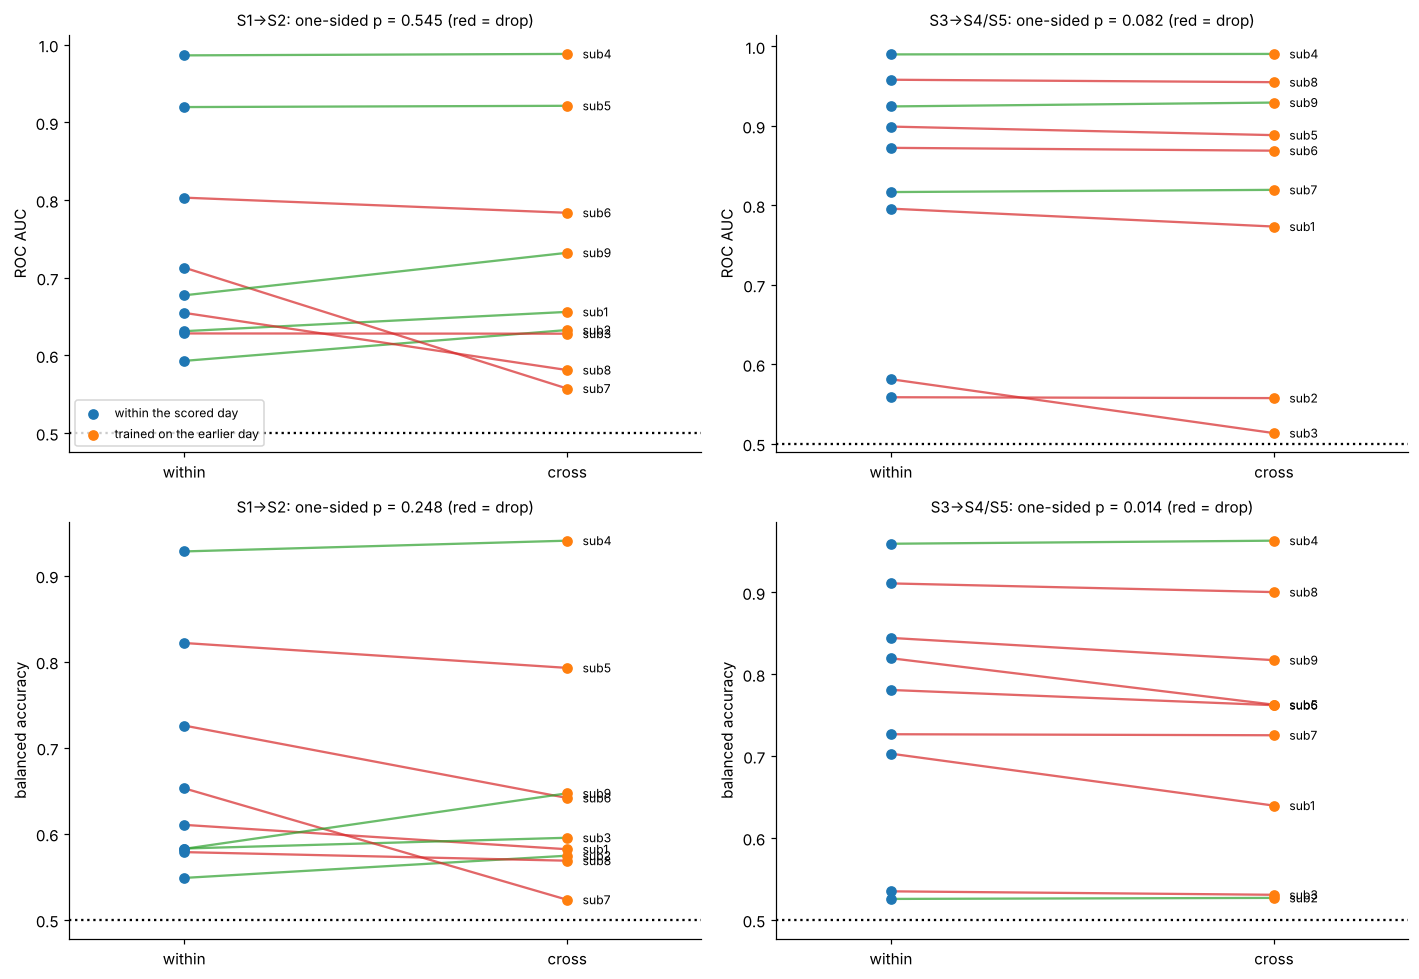

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, tname in enumerate(TRANSFERS):
    for row, (w, c, lab) in enumerate([("within", "cross", "ROC AUC"), ("within_bacc", "cross_bacc", "balanced accuracy")]):
        ax = axes[row, col]
        W_, C_ = table("A", tname, w), table("A", tname, c)
        for subj in SUBJECTS:
            ax.plot([0, 1], [W_[subj], C_[subj]], color="C3" if W_[subj] > C_[subj] else "C2", alpha=0.7)
            ax.text(1.04, C_[subj], f"sub{subj}", fontsize=8, va="center")
        ax.scatter(np.zeros(9), W_, color="C0", zorder=3, label="within the scored day")
        ax.scatter(np.ones(9), C_, color="C1", zorder=3, label="trained on the earlier day")
        p = h1[tname].pvalue if row == 0 else h1_tab.loc[h1_tab.transfer == tname, "p_bacc"].iloc[0]
        ax.axhline(0.5, color="k", ls=":"); ax.set_xticks([0, 1]); ax.set_xticklabels(["within", "cross"]); ax.set_xlim(-0.3, 1.35)
        ax.set_ylabel(lab); ax.set_title(f"{tname}: one-sided p = {p:.3f} (red = drop)", fontsize=10)
axes[0, 0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

### V3 — Is the cross-session decoder better than chance?
One-sided Mann–Whitney test on all scored trials (equivalent to AUC > 0.5). The scores are the average of the 20 subsampled
decoders; for H1b the S4 and S5 trials are pooled (each scored by its own matched-size S3 decoder).

In [26]:
chance = pd.DataFrame({tname: {subj: mannwhitneyu(R[("A", tname, subj)]["scores"][R[("A", tname, subj)]["y"] == 1],
                                                  R[("A", tname, subj)]["scores"][R[("A", tname, subj)]["y"] == 0],
                                                  alternative="greater").pvalue for subj in SUBJECTS} for tname in TRANSFERS})
chance.index.name = "subject"
print("Above chance (p < 0.05):", {t: int((chance[t] < ALPHA).sum()) for t in TRANSFERS}, "of 9")
chance

Above chance (p < 0.05): {'S1→S2': 7, 'S3→S4/S5': 7} of 9


,S1→S2,S3→S4/S5
subject,,
1,1.375e-03,1.004e-18
2,4.581e-03,7.166e-02
3,3.250e-03,2.010e-01
4,2.080e-23,5.132e-52
5,3.713e-18,1.843e-35
6,4.771e-08,3.505e-30
7,8.016e-02,1.182e-22
8,5.677e-02,4.137e-47
9,1.959e-05,4.492e-41


### Every subject and every day in one picture

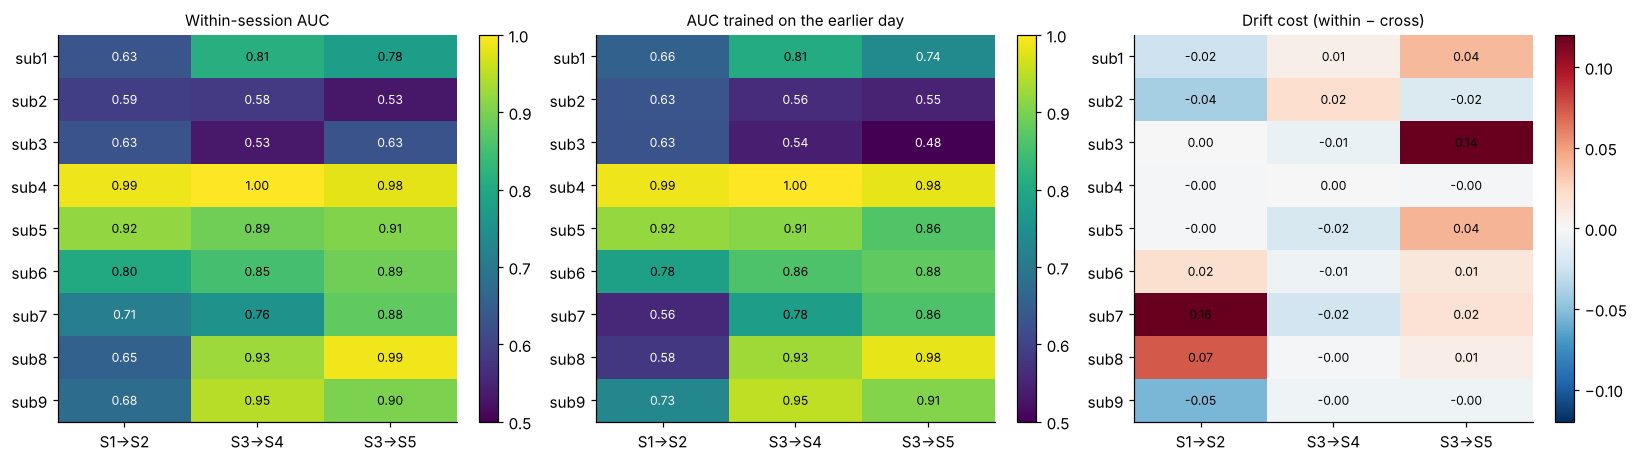

In [27]:
cols = [("S1→S2", 2), ("S3→S4/S5", 4), ("S3→S4/S5", 5)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (key, title, cmap, vlim) in zip(axes, [("within", "Within-session AUC", "viridis", (0.5, 1)),
                                               ("cross", "AUC trained on the earlier day", "viridis", (0.5, 1)),
                                               ("drift", "Drift cost (within − cross)", "RdBu_r", (-0.12, 0.12))]):
    M = np.array([[R[("A", t, subj)]["per_session"][s][key] for (t, s) in cols] for subj in SUBJECTS])
    im = ax.imshow(M, cmap=cmap, vmin=vlim[0], vmax=vlim[1], aspect="auto")
    for i in range(9):
        for j in range(3):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="w" if (cmap == "viridis" and M[i, j] < 0.75) else "k")
    ax.set_xticks(range(3)); ax.set_xticklabels(["S1→S2", "S3→S4", "S3→S5"]); ax.set_yticks(range(9))
    ax.set_yticklabels([f"sub{s}" for s in SUBJECTS]); ax.set_title(title, fontsize=10); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

### Why the team's first notebook found no drift: training size
Same scored day (S2), different training sets: matched size (the fair test), all of S1, and MOABB-style "all other four sessions"
(which also includes days *after* S2).

,median
within S2 (matched),0.677
S1 (matched),0.656
S1 (all trials),0.670
4 other sessions,0.697
n other,468.000


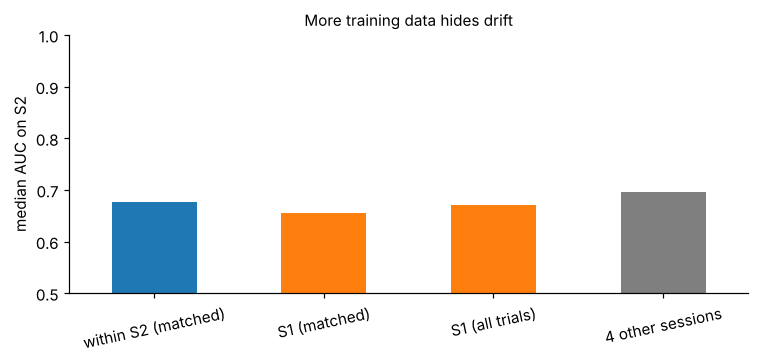

In [28]:
size_rows = []
for subj in SUBJECTS:
    others = [s for s in SESSIONS if s != 2]
    Xo = np.vstack([features(subj, s) for s in others]); yo = np.concatenate([S[(subj, s)]["y"] for s in others])
    ko = np.concatenate([S[(subj, s)]["keep_eog"] for s in others])
    loso = compare(subj, 0, 2, train_override=(Xo, yo, ko), matched=False)
    size_rows.append({"subject": subj, "within S2 (matched)": R[("A", "S1→S2", subj)]["within"],
                      "S1 (matched)": R[("A", "S1→S2", subj)]["cross"],
                      "S1 (all trials)": compare(subj, 1, 2, matched=False)["cross"],
                      "4 other sessions": loso["cross"], "n other": int(ko.sum())})
size_tab = pd.DataFrame(size_rows).set_index("subject")
display(size_tab.median().round(3).to_frame("median"))
ax = size_tab.drop(columns="n other").median().plot(kind="bar", figsize=(7, 3.4), rot=12, ylim=(0.5, 1), color=["C0", "C1", "C1", "C7"])
ax.set_ylabel("median AUC on S2"); ax.set_title("More training data hides drift", fontsize=10); plt.tight_layout(); plt.show()

### Drift in feature space
One subject, chosen by a fixed rule: among subjects decoded well on session 3 (within-session AUC ≥ 0.8), the one whose mean mu
power moved most between session 3 and sessions 4–5 (no decoder involved). Each panel is one day: trials as points in the plane
of log mu power at C3 (x) and C4 (y); the black line is a 2-feature decoder fitted on **session 3 only** and kept fixed. Top: raw features (A). Bottom: session
z-scored (D). Accuracy of the fixed line on each day is in the title (illustration only; the real decoder uses all 6 features).

Shown: sub7 (mean |shift| of log mu power from S3 to S4/S5 = 0.31 log units)


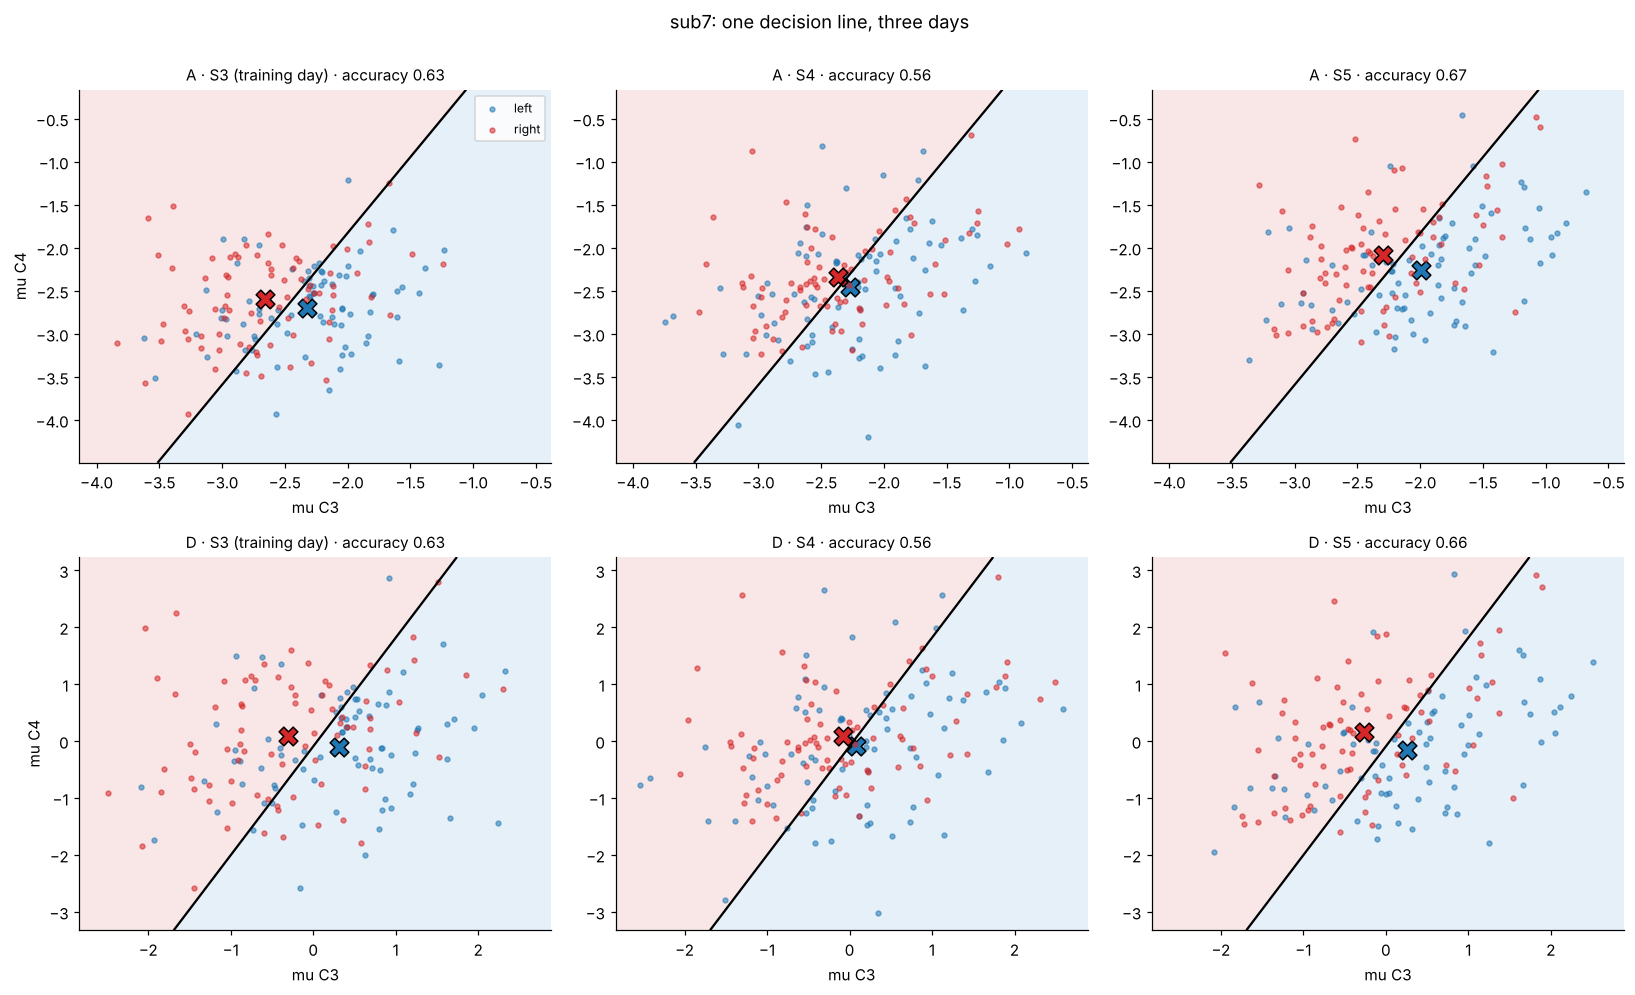

In [29]:
good = [s for s in SUBJECTS if within_by_sess.loc[s, 3] >= 0.8]
shift = {s: np.mean([abs(features(s, t)[:, [0, 2]].mean() - features(s, 3)[:, [0, 2]].mean()) for t in (4, 5)]) for s in good}
worst = max(shift, key=shift.get)
print(f"Shown: sub{worst} (mean |shift| of log mu power from S3 to S4/S5 = {shift[worst]:.2f} log units)")
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, variant in enumerate(["A", "D"]):
    F = {s: features(worst, s, variant)[:, [0, 2]] for s in (3, 4, 5)}
    k3 = S[(worst, 3)]["keep_eog"]
    clf2 = make_clf().fit(F[3][k3], S[(worst, 3)]["y"][k3])
    allx = np.vstack(list(F.values())); lo, hi = allx.min(0) - 0.3, allx.max(0) + 0.3
    gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 200), np.linspace(lo[1], hi[1], 200))
    gp = clf2.predict_proba(np.c_[gx.ravel(), gy.ravel()])[:, 1].reshape(gx.shape)
    for ax, s in zip(axes[row], (3, 4, 5)):
        y = S[(worst, s)]["y"]
        ax.contourf(gx, gy, gp, levels=[0, 0.5, 1], colors=["#d6e6f5", "#f6d8d8"], alpha=0.6)
        ax.contour(gx, gy, gp, levels=[0.5], colors="k")
        for c, col, lab in [(0, "C0", "left"), (1, "C3", "right")]:
            ax.scatter(*F[s][y == c].T, s=10, color=col, alpha=0.55, label=lab)
            ax.scatter(*F[s][y == c].mean(0), marker="X", s=150, color=col, ec="k")
        acc = balanced_accuracy_score(y, clf2.predict(F[s]))
        ax.set_title(f"{variant} · S{s}{' (training day)' if s == 3 else ''} · accuracy {acc:.2f}", fontsize=10)
        ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_xlabel("mu C3")
    axes[row, 0].set_ylabel("mu C4")
axes[0, 0].legend(fontsize=8)
plt.suptitle(f"sub{worst}: one decision line, three days", y=1.0); plt.tight_layout(); plt.show()

## 12. H2 — Do the fixes reduce the drift cost?
Outcome per subject: drift cost averaged over the two transfers (S1→S2 and S3→S4/S5). One-sided Wilcoxon (fix lowers the drift
cost), Holm-corrected over the two fixes. A fix counts only if cross-session AUC does not drop significantly (two-sided Wilcoxon) —
a descriptive check: with 9 subjects it cannot prove the fix is "no worse". Within- and cross-session AUC are shown side by side,
because a fix can lower the drift cost simply by making within-session decoding worse.

Note on D: z-scoring is one shift-and-scale per session, and the decoder standardises features anyway, so within-session results
for D equal those for A by construction. Any effect of D shows up only in cross-session AUC.

In [30]:
def avg_over_transfers(variant, key):
    return pd.Series({subj: np.mean([R[(variant, t, subj)][key] for t in TRANSFERS]) for subj in SUBJECTS})

dA, cA = avg_over_transfers("A", "drift"), avg_over_transfers("A", "cross")
h2_rows = []
for v in ("C", "D"):
    dV, cV = avg_over_transfers(v, "drift"), avg_over_transfers(v, "cross")
    wA, wV = avg_over_transfers("A", "within"), avg_over_transfers(v, "within")
    h2_rows.append(dict(fix=f"{v}: {VARIANTS[v]}", median_within_change=(wV - wA).median(),
                        median_drift_A=dA.median(), median_drift_fix=dV.median(),
                        median_reduction=(dA - dV).median(), n_reduced=int((dA - dV > 0).sum()),
                        p_reduction=wilcoxon(dA - dV, alternative="greater").pvalue,
                        median_cross_A=cA.median(), median_cross_fix=cV.median(), median_cross_change=(cV - cA).median(),
                        p_cross_change=wilcoxon(cV - cA).pvalue))
h2 = pd.DataFrame(h2_rows).set_index("fix")
p_adj = np.minimum(1, np.maximum.accumulate(np.sort(h2.p_reduction.values) * np.array([2, 1])))      # Holm, two tests
h2["p_reduction_holm"] = pd.Series(p_adj, index=h2.p_reduction.sort_values().index)
h2["supported"] = (h2.p_reduction_holm < ALPHA) & ~((h2.p_cross_change < ALPHA) & (h2.median_cross_change < 0))
display(h2.round(4))

,median_within_change,median_drift_A,median_drift_fix,median_reduction,n_reduced,p_reduction,median_cross_A,median_cross_fix,median_cross_change,p_cross_change,p_reduction_holm,supported
fix,,,,,,,,,,,,
C: baseline-relative,-0.106,0.005,0.003,-3.000e-03,3,0.455,0.768,0.664,-6.590e-02,0.004,0.91,False
D: session z-scored,0.000,0.005,0.010,3.000e-04,5,0.590,0.768,0.770,3.000e-04,0.910,0.91,False


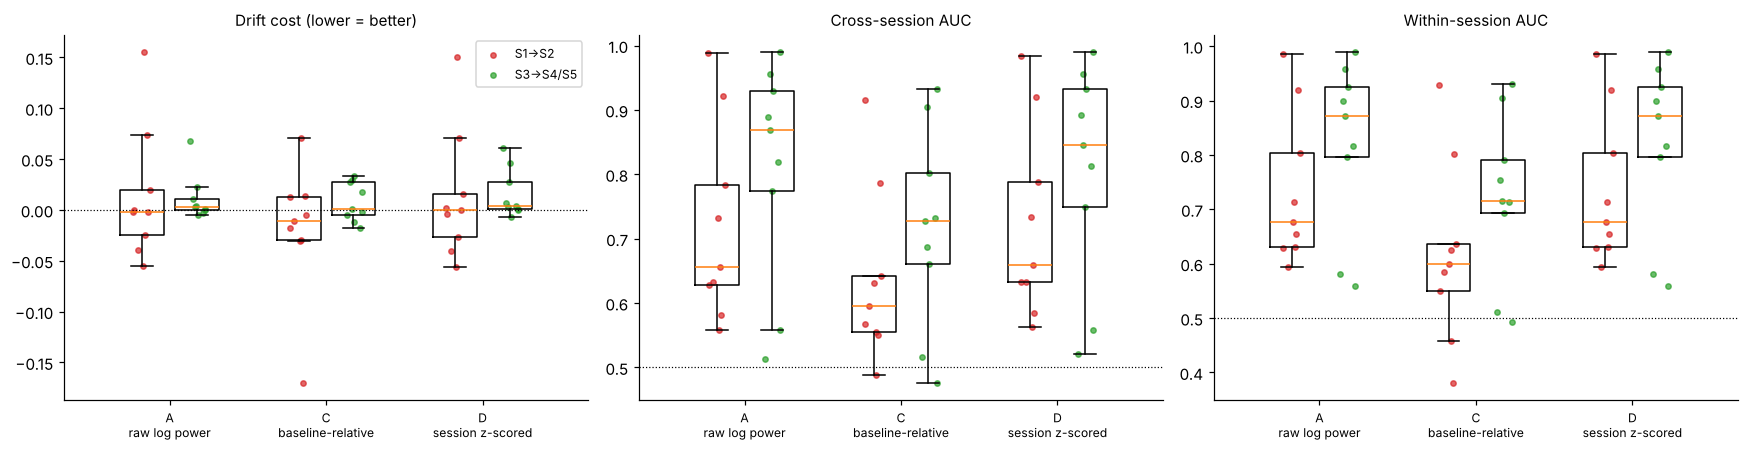

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
pos = {v: i for i, v in enumerate(VARIANTS)}
for ax, (key, title, ref) in zip(axes, [("drift", "Drift cost (lower = better)", 0), ("cross", "Cross-session AUC", 0.5),
                                        ("within", "Within-session AUC", 0.5)]):
    for k, tname in enumerate(TRANSFERS):
        for v in VARIANTS:
            vals = table(v, tname, key)
            x = pos[v] + (k - 0.5) * 0.35
            ax.boxplot(vals, positions=[x], widths=0.28, showfliers=False)
            ax.scatter(np.full(9, x) + np.random.default_rng(k).uniform(-0.06, 0.06, 9), vals, s=12,
                       color="C3" if tname == "S1→S2" else "C2", alpha=0.7, label=tname if v == "A" else None)
    ax.axhline(ref, color="k", ls=":", lw=0.8); ax.set_xticks(range(3)); ax.set_xticklabels([f"{v}\n{VARIANTS[v]}" for v in VARIANTS], fontsize=8)
    ax.set_title(title, fontsize=10)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 13. Validation checks and sensitivity analyses
### V2 — chance results when there is nothing to learn
Two shuffle checks, 20 times per subject and transfer:
- **within side:** labels shuffled inside the training folds of the within-session CV (scored labels kept). If trials of the
  held-out run leaked into training, this AUC would stay above 0.5;
- **cross side:** training-session labels shuffled.
Both means must stay at 0.5.

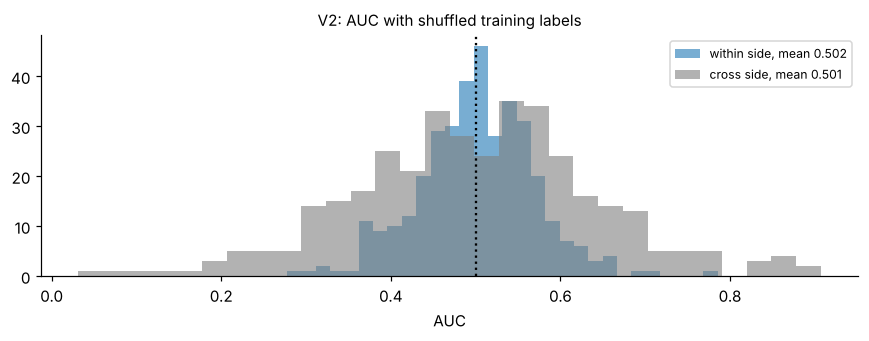

V2 passed: means within 0.502, cross 0.501. A wide spread is expected: a decoder trained on noise points in a random direction, which can line up with or against well-separated classes.


In [32]:
rng = np.random.default_rng(SEED)
shuf, shuf_w = [], []
for k in range(N_SHUFFLE):
    for subj in SUBJECTS:
        for tname, (s_tr, scored) in TRANSFERS.items():
            r = S[(subj, s_tr)]
            ov = (features(subj, s_tr), rng.permutation(r["y"]), r["keep_eog"])
            res_ = [compare(subj, 0, s, train_override=ov, n_rep=1, shuffle_within=True, seed_offset=k + 1) for s in scored]
            shuf.append(np.mean([x["cross"] for x in res_])); shuf_w.append(np.mean([x["within"] for x in res_]))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(shuf_w, bins=30, color="C0", alpha=0.6, label=f"within side, mean {np.mean(shuf_w):.3f}")
ax.hist(shuf, bins=30, color="grey", alpha=0.6, label=f"cross side, mean {np.mean(shuf):.3f}")
ax.axvline(0.5, color="k", ls=":"); ax.legend(fontsize=8)
ax.set_title("V2: AUC with shuffled training labels", fontsize=10); ax.set_xlabel("AUC")
plt.tight_layout(); plt.show()
ok = abs(np.mean(shuf) - 0.5) < 0.03 and abs(np.mean(shuf_w) - 0.5) < 0.03
print(f"V2 {'passed' if ok else 'FAILED'}: means within {np.mean(shuf_w):.3f}, cross {np.mean(shuf):.3f}. A wide spread is expected: "
      "a decoder trained on noise points in a random direction, which can line up with or against well-separated classes.")

### Sensitivity analyses (planned in advance)

In [33]:
def run_condition(variants=("A", "D"), **kw):
    return {(v, t, subj): transfer(subj, t, variant=v, **kw) for v in variants for t in TRANSFERS for subj in SUBJECTS}

def summarise(Rc, label):
    d1 = pd.Series({s: Rc[("A", "S1→S2", s)]["drift"] for s in SUBJECTS})
    d2 = pd.Series({s: Rc[("A", "S3→S4/S5", s)]["drift"] for s in SUBJECTS})
    dA_ = pd.Series({s: np.mean([Rc[("A", t, s)]["drift"] for t in TRANSFERS]) for s in SUBJECTS})
    dD_ = pd.Series({s: np.mean([Rc[("D", t, s)]["drift"] for t in TRANSFERS]) for s in SUBJECTS})
    return {"condition": label, "H1a drift": d1.median(), "H1a p": wilcoxon(d1, alternative="greater").pvalue,
            "H1b drift": d2.median(), "H1b p": wilcoxon(d2, alternative="greater").pvalue,
            "D reduction": (dA_ - dD_).median(), "D p": wilcoxon(dA_ - dD_, alternative="greater").pvalue}

t0 = time.time()
sens = pd.DataFrame([
    summarise(R, "main analysis"),
    summarise(run_condition(clean=False), "(a) no trial cleaning"),
    summarise(run_condition(version="noeog"), "(b) no EOG regression"),
    summarise(run_condition(first_block=True), "(c) new day z-scored from its first run; runs 2+ scored"),
    summarise(run_condition(matched=False), "(d) unmatched training size"),
    summarise(run_condition(pooled=True), "(f) pooled out-of-fold AUC (v1 method)"),
]).set_index("condition")
print(f"Sensitivity analyses in {time.time() - t0:.0f} s")
display(sens.round(4))

# (e) MOABB-style training on all other four sessions, scored on S2, S4, S5
loso_rows = []
for subj in SUBJECTS:
    for s_te in (2, 4, 5):
        others = [s for s in SESSIONS if s != s_te]
        ov = (np.vstack([features(subj, s) for s in others]), np.concatenate([S[(subj, s)]["y"] for s in others]),
              np.concatenate([S[(subj, s)]["keep_eog"] for s in others]))
        r = compare(subj, 0, s_te, train_override=ov, matched=False)
        loso_rows.append(dict(subject=subj, scored=s_te, within=r["within"], loso=r["cross"]))
loso = pd.DataFrame(loso_rows)
dl = loso.groupby("subject").apply(lambda g: (g.within - g.loso).mean())
print(f"(e) leave-one-session-out training: median within − LOSO = {dl.median():+.3f} "
      f"(negative = training on 4 sessions beats the scored day itself); positive in {(dl > 0).sum()}/9")

Sensitivity analyses in 110 s


,H1a drift,H1a p,H1b drift,H1b p,D reduction,D p
condition,,,,,,
main analysis,-0.002,0.545,3.100e-03,0.082,3.000e-04,0.590
(a) no trial cleaning,0.003,0.213,1.600e-03,0.213,-5.000e-04,0.787
(b) no EOG regression,-0.001,0.590,5.400e-03,0.082,-2.400e-03,0.898
(c) new day z-scored from its first run; runs 2+ scored,-0.002,0.500,8.600e-03,0.065,-3.700e-03,0.787
(d) unmatched training size,-0.001,0.590,6.000e-04,0.180,-2.000e-04,0.633
(f) pooled out-of-fold AUC (v1 method),-0.011,0.674,1.800e-03,0.455,8.000e-04,0.590


(e) leave-one-session-out training: median within − LOSO = -0.016 (negative = training on 4 sessions beats the scored day itself); positive in 2/9


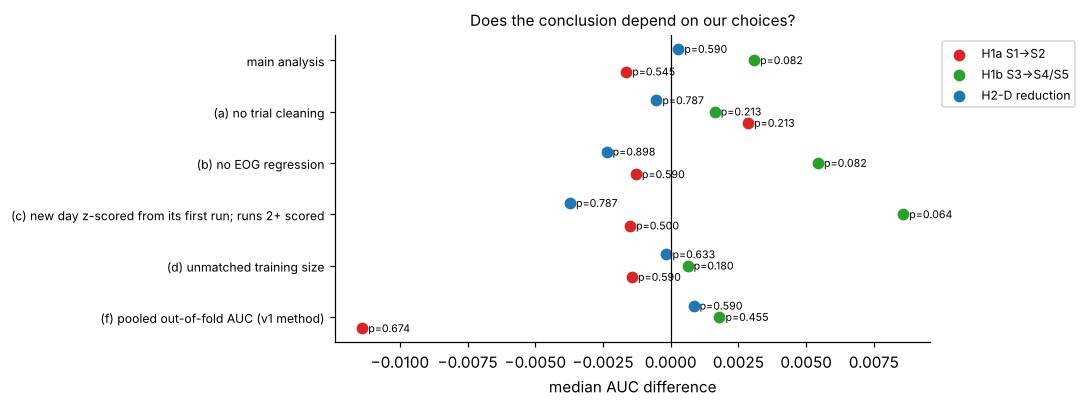

In [34]:
fig, ax = plt.subplots(figsize=(10, 3.8))
y0 = np.arange(len(sens))[::-1]
for k, (col, lab, colr) in enumerate([("H1a drift", "H1a S1→S2", "C3"), ("H1b drift", "H1b S3→S4/S5", "C2"),
                                      ("D reduction", "H2-D reduction", "C0")]):
    ax.scatter(sens[col], y0 + (k - 1) * 0.22, color=colr, s=45, label=lab)
    pcol = col.split()[0] + " p"
    for yy, (_, r) in zip(y0 + (k - 1) * 0.22, sens.iterrows()):
        ax.text(r[col], yy, f"  p={r[pcol]:.3f}", fontsize=7, va="center")
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(y0); ax.set_yticklabels(sens.index, fontsize=8)
ax.set_xlabel("median AUC difference"); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.set_title("Does the conclusion depend on our choices?", fontsize=10)
plt.tight_layout(); plt.show()

## 14. Results summary (generated from the numbers above)

In [35]:
lines = [
    f"Data: 9 subjects, {audit.trials.sum()} trials; {cleaning.removed.sum()} trials left out of training whenever their session was "
    f"used for training (expert flags + variance outliers); all trials scored. EOG regression from the calibration recording in "
    f"{(eog_tab.eog_fit_on.str.startswith('calibration')).sum()} of 45 sessions.",
    "Median within-session AUC per session: " + ", ".join(f"S{s} {v:.3f}" for s, v in within_by_sess.median().items()) + ".",
] + [f"{r.Index} {r.transfer} (training trials, sub1: {r.n_train_example}): within {r.within_auc:.3f} vs cross {r.cross_auc:.3f}; drift cost median "
     f"{r.drift_median:+.3f} (positive in {r.n_positive}/9), one-sided p = {r.p:.4f}; balanced-accuracy drift {r.drift_bacc_median:+.3f}, "
     f"p = {r.p_bacc:.4f}." for r in h1_tab.itertuples()] + [
    f"H2 {i}: drift reduction median {r.median_reduction:+.3f}, Holm p = {r.p_reduction_holm:.4f}; cross AUC change "
    f"{r.median_cross_change:+.3f} (p = {r.p_cross_change:.4f}) → {'SUPPORTED' if r.supported else 'NOT SUPPORTED'}."
    for i, r in h2.iterrows()] + [
    "Training-size effect (median AUC on S2): " + ", ".join(f"{k} {v:.3f}" for k, v in size_tab.drop(columns='n other').median().items()) + ".",
    f"V2 shuffled-label mean AUC {np.mean(shuf):.3f}. Above-chance cross-session decoding: " +
    ", ".join(f"{t} {int((chance[t] < ALPHA).sum())}/9" for t in TRANSFERS) + ".",
]
print("\n\n".join(lines))

Data: 9 subjects, 6520 trials; 1272 trials left out of training whenever their session was used for training (expert flags + variance outliers); all trials scored. EOG regression from the calibration recording in 43 of 45 sessions.

Median within-session AUC per session: S1 0.731, S2 0.649, S3 0.895, S4 0.843, S5 0.894.

H1a (primary) S1→S2 (training trials, sub1: 79): within 0.677 vs cross 0.656; drift cost median -0.002 (positive in 4/9), one-sided p = 0.5449; balanced-accuracy drift +0.010, p = 0.2480.

H1b (secondary) S3→S4/S5 (training trials, sub1: 81 / 83): within 0.872 vs cross 0.869; drift cost median +0.003 (positive in 6/9), one-sided p = 0.0820; balanced-accuracy drift +0.011, p = 0.0137.

H2 C: baseline-relative: drift reduction median -0.003, Holm p = 0.9102; cross AUC change -0.066 (p = 0.0039) → NOT SUPPORTED.

H2 D: session z-scored: drift reduction median +0.000, Holm p = 0.9102; cross AUC change +0.000 (p = 0.9102) → NOT SUPPORTED.

Training-size effect (median AUC o

## 15. Interpretation, deviations and limitations
*Written after the final run; numbers are deterministic (fixed seeds).*

**Answer: no measurable drift in class separation.** A decoder trained on an earlier day separated left from right hand on a new
day as well as a decoder trained on that same day, once both had the same number of training trials:
- **H1a, S1 → S2:** median drift cost −0.002 AUC, 4 of 9 subjects positive, p = 0.55. Not supported.
- **H1b, S3 → S4/S5:** +0.003 AUC, 6 of 9 positive, p = 0.08. Not supported.

The result holds in all six sensitivity analyses.

**What does drift — the decision threshold, a little.** In the feedback sessions, balanced accuracy at the default threshold
drops slightly but consistently: +0.011 drift, p = 0.014 (secondary metric). AUC ignores where the threshold sits; accuracy does
not. So on a new day the whole score distribution shifts a bit while the left/right ordering stays. This matches the feature
plots: overall mu power moves between days (Section 9 i) while the class contrast on the head and the decoder weights stay
similar (cosine similarity 0.63–0.84 between days).

**Fixes (H2) — not supported, as expected when there is no drift in AUC to remove.**
- C (baseline-relative) made decoding clearly worse: cross-session AUC −0.066, p = 0.004; within-session AUC −0.11. A 1-s
  single-trial baseline adds noise, and in feedback sessions this window falls on a rising and falling mu transition.
- D (session z-scoring, the team's README hypothesis) changed nothing in AUC, by construction for the within side. The realistic
  version, which uses only the new day's first run (sensitivity c), was not better either.

**Why the team's first notebook "found no drift" for the wrong reason:** MOABB's leave-one-session-out evaluation trains on four
sessions, including days *after* the scored one. That beats training on the scored day itself in 7 of 9 subjects (median +0.016
AUC), because more data outweighs any day-to-day change. Only matched-size, past-only comparisons can test drift.

**Why no drift, physiologically.** Subjects improve with feedback: within-session AUC rises from 0.65–0.73 in screening to
0.84–0.90 in feedback sessions. The contralateral mu pattern gets stronger rather than weaker, so a decoder from an earlier day
still points in the right direction.

**Deviations from the plan and corrections (all before interpretation):**
1. *Independent code review:* within-session AUC was planned as one AUC over pooled out-of-fold scores (as in v1). This penalises
   the within side, because separately fitted fold models have different offsets, which biases drift toward zero. The main
   analysis now scores both sides run by run on identical trials; the pooled method is sensitivity (f).
2. In sensitivity (c) only the scored day uses first-run statistics; the training day is normalised with all its trials.
3. The V2 within-side shuffle first reused the same permutation in every repetition (a seeding bug), giving a misleading mean of
   0.469. Fixed: 0.502.
4. The H2 condition "must not lower cross-session AUC" is implemented as "no significant drop" — a descriptive check, not a proof
   that the fix is no worse.

**Limitations:**
- 9 subjects; small effects (around 0.01 AUC) cannot be detected reliably.
- Runs in feedback sessions were verified from the ~23-s pauses between them. Screening sessions have irregular pauses, so their
  runs are contiguous blocks of 20 trials that may not match the real runs exactly. A mismatch could only inflate within-session AUC
  (favouring H1), which was nevertheless not supported.
- Matched training sets are small (≈ 80 trials).
- S1 → S2 changes the day but S3 → S4/S5 also follows learning with feedback, so "no drift" here means "no net loss", not "nothing
  changed".
- The hypotheses were written before v1, but v1's results were known before this run. Only H1b was new.

## References
- Leeb R. et al. (2007). Brain–computer communication: motivation, aim, and impact of exploring a virtual apartment.
  *IEEE TNSRE* 15(4):473–482 — the dataset.
- Pfurtscheller G., Lopes da Silva F. H. (1999). Event-related EEG/MEG synchronization and desynchronization: basic principles.
  *Clinical Neurophysiology* 110:1842–1857.
- Shenoy P. et al. (2006). Towards adaptive classification for BCI. *J. Neural Eng.* 3:R13–R23 — non-stationarity between sessions.
- Mayka M. A. et al. (2006). Three-dimensional locations and boundaries of motor and premotor cortices. *NeuroImage* 31:1453–1474.
- Gramfort A. et al. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience* 7:267.
- Jayaram V., Barachant A. (2018). MOABB: trustworthy algorithm benchmarking for BCIs. *J. Neural Eng.* 15:066011.
- Abibullaev B. ROBT613 BCI Workshop, notebooks 00–06; lecture *Motor-Imagery BCI decoding with CSP and LDA*.